# 1A pilot v2.2 — audit and corrected analysis of the v2.1 run (CPU only)

> **Tóm tắt (VI):** Notebook này **không chạy mô hình**. Nó đọc kết quả v2.1 trên Drive và làm 4 việc: (1) kiểm tra lại dữ liệu đầu vào và nhiễu; (2) kiểm tra output của mô hình (đủ dòng, nhất quán, label mass, mô hình có "sụp" về một nhãn không, câu trả lời tự do trông thế nào); (3) sửa các phân tích còn yếu của v2.1; (4) vẽ hình và bảng cho bài báo. Chạy trên **runtime CPU**, khoảng 10–15 phút, gần như không tốn CU.

**What v2.2 fixes from the v2.1 analysis**

| v2.1 analysis issue | v2.2 |
|---|---|
| `broken` was a *level* (broken syllables in the noisy text), so it partly measured content (names, English words) | **Δbroken** = noisy − clean |
| Model-level correlations pooled all noise levels, so they mostly measured "more noise ⇒ more drop" | Correlations **within each condition**, plus a regression with condition and task fixed effects |
| Qwen3 and bloomz-1b7/3b put ~0% probability on the labels | Every result in two tiers: **gated** and **reliable** (gated *and* clean label mass ≥ 50%) |
| ViHSD "real noise" groups were not controlled for the label | Logistic model with **label and model fixed effects** |
| Scale trends had no uncertainty | **Paired bootstrap CIs** (same item resamples for every model in a task) |
| SEs clustered by item, although ViMMRC items share articles and XNLI items share premises | Clustered by **article** (ViMMRC) and **premise** (XNLI) |
| Items the noise does not change (10% of ViHSD under `strip`) diluted the drop | Drop also reported on **changed items only** |
| No test that holds the tokenization fixed | **Same-tokenizer test**: for the same noisy item and the same tokens, does the model that finds it more surprising flip more? |

Not fixable without a GPU (left for v3): re-scoring Qwen3/bloomz with their preferred answer format, and ViMMRC NLL on question + options only.

**Outputs:** `MyDrive/llm-research/1A-pilot-v2.2/` → `figures/` (PNG + PDF), `tables/` (CSV + LaTeX), `audit/`, `key_numbers.json`.

## 0. Setup

In [2]:
import sys, os, json, re, ast, random, unicodedata, difflib, warnings
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/llm-research"
else:
    ROOT = os.environ.get("PILOT_ROOT", "outputs")
IN_DIR = f"{ROOT}/1A-pilot-v2.1"
OUT_DIR = f"{ROOT}/1A-pilot-v2.2"
for d in ["figures", "tables", "audit"]:
    os.makedirs(f"{OUT_DIR}/{d}", exist_ok=True)
print("reading", IN_DIR, "→ writing", OUT_DIR)

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from IPython.display import display
warnings.filterwarnings("ignore", category=mpl.MatplotlibDeprecationWarning)
warnings.filterwarnings("ignore", message="An input array is constant")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
KEY = {}  # headline numbers, saved to key_numbers.json at the end

Mounted at /content/drive
reading /content/drive/MyDrive/llm-research/1A-pilot-v2.1 → writing /content/drive/MyDrive/llm-research/1A-pilot-v2.2


In [3]:
# Same settings as v2.1
SEED = 42
TASKS = ["vsfc", "vsmec", "vihsd", "xnli", "vimmrc"]
CONDITIONS = ["clean", "partial25", "partial50", "partial75", "strip", "teencode", "mixed"]
NOISY = CONDITIONS[1:]
LEVEL = {"clean": 0, "partial25": 25, "partial50": 50, "partial75": 75, "strip": 100}
MIN_ABOVE_CHANCE = 0.12
MIN_LABEL_MASS = 0.5
B = 2000  # bootstrap resamples

MODEL_INFO = {  # name: (family, size in billions), v2.1 + gated
    "Qwen/Qwen2.5-1.5B-Instruct": ("Qwen2.5", 1.5), "Qwen/Qwen2.5-3B-Instruct": ("Qwen2.5", 3.1),
    "Qwen/Qwen2.5-7B-Instruct": ("Qwen2.5", 7.6),
    "Qwen/Qwen3-1.7B": ("Qwen3", 1.7), "Qwen/Qwen3-4B": ("Qwen3", 4.0), "Qwen/Qwen3-8B": ("Qwen3", 8.2),
    "SeaLLMs/SeaLLMs-v3-1.5B-Chat": ("SeaLLMs-v3", 1.5), "SeaLLMs/SeaLLMs-v3-7B-Chat": ("SeaLLMs-v3", 7.6),
    "vilm/vinallama-2.7b-chat": ("VinaLLaMA", 2.7), "vilm/vinallama-7b-chat": ("VinaLLaMA", 6.9),
    "bigscience/bloomz-1b7": ("bloomz", 1.7), "bigscience/bloomz-3b": ("bloomz", 3.0), "bigscience/bloomz-7b1": ("bloomz", 7.1),
    "microsoft/Phi-3.5-mini-instruct": ("Phi-3.5", 3.8),
    "mistralai/Mistral-7B-Instruct-v0.3": ("Mistral", 7.2), "Viet-Mistral/Vistral-7B-Chat": ("Mistral", 7.3),
    "meta-llama/Llama-3.2-3B-Instruct": ("Llama-3", 3.2), "meta-llama/Llama-3.1-8B-Instruct": ("Llama-3", 8.0),
    "CohereLabs/aya-expanse-8b": ("Aya", 8.0),
}
FAMILIES = ["Qwen2.5", "Qwen3", "SeaLLMs-v3", "VinaLLaMA", "bloomz", "Phi-3.5", "Mistral", "Llama-3", "Aya"]

def pred_path(name, task):
    return f"{IN_DIR}/preds/{task}/{name.replace('/', '__')}.csv"

MODELS = [m for m in MODEL_INFO if any(os.path.exists(pred_path(m, t)) for t in TASKS)]
MODELS.sort(key=lambda m: (FAMILIES.index(MODEL_INFO[m][0]), MODEL_INFO[m][1]))
SHORT = {m: m.split("/")[1].replace("-Instruct", "").replace("-Chat", "").replace("-chat", "").replace("-mini-instruct", "-mini")
         for m in MODELS}
print(len(MODELS), "models with results:", [SHORT[m] for m in MODELS])

16 models with results: ['Qwen2.5-1.5B', 'Qwen2.5-3B', 'Qwen2.5-7B', 'Qwen3-1.7B', 'Qwen3-4B', 'Qwen3-8B', 'SeaLLMs-v3-1.5B', 'SeaLLMs-v3-7B', 'vinallama-2.7b', 'vinallama-7b', 'bloomz-1b7', 'bloomz-3b', 'bloomz-7b1', 'Phi-3.5-mini', 'Mistral-7B-v0.3', 'Llama-3.2-3B']


In [4]:
# Figure style: one family = one colour, everywhere (validated categorical palette, fixed order)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#52514e"]
FAM_COLOR = dict(zip(FAMILIES, PALETTE))
TASK_NAME = {"vsfc": "VSFC (sentiment)", "vsmec": "VSMEC (emotion)", "vihsd": "ViHSD (hate speech)",
             "xnli": "XNLI-vi (inference)", "vimmrc": "ViMMRC (reading)"}
SEQ = mpl.colors.LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2a28",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5, "pdf.fonttype": 42,
})

def save(fig, name):
    fig.savefig(f"{OUT_DIR}/figures/{name}.png", bbox_inches="tight")
    fig.savefig(f"{OUT_DIR}/figures/{name}.pdf", bbox_inches="tight")
    plt.show()

def save_table(df, name, caption="", floatfmt="%.2f"):
    df.to_csv(f"{OUT_DIR}/tables/{name}.csv")
    try:
        df.to_latex(f"{OUT_DIR}/tables/{name}.tex", float_format=floatfmt, caption=caption, label=f"tab:{name}", na_rep="--")
    except Exception as e:
        print("latex export failed:", name, repr(e)[:100])

## 1. Input data audit

The tasks are rebuilt from Hugging Face with **the exact v2.1 code** (noise generator and task specs are copied unchanged), then compared character by character with `noisy_items.csv` from the run. Then each noise condition is checked against what it claims to do.

In [5]:
# ---- copied unchanged from 1A_pilot_v2.1.ipynb, section 2 ----
def strip_diacritics(s):
    s = s.replace("đ", "d").replace("Đ", "D")
    s = unicodedata.normalize("NFD", s)
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return unicodedata.normalize("NFC", s)

def partial_strip(text, rate, rng):
    words = text.split(" ")
    candidates = [i for i, w in enumerate(words) if strip_diacritics(w) != w]
    chosen = set(rng.sample(candidates, round(rate * len(candidates))))
    return " ".join(strip_diacritics(w) if i in chosen else w for i, w in enumerate(words))

TEENCODE = {
    "giáo viên": "gv", "giảng viên": "gv", "sinh viên": "sv", "bài tập": "bt", "học sinh": "hs",
    "không": "ko", "được": "dc", "gì": "j", "với": "vs", "mình": "mk", "rồi": "r",
    "vậy": "v", "bạn": "bn", "quá": "wa", "nhiều": "nhìu", "người": "ng", "trước": "trc",
    "cũng": "cx", "thôi": "thui", "biết": "bít", "yêu": "iu", "giờ": "h",
    "nhưng": "nhg", "lắm": "lém", "thích": "thik", "những": "nhữg", "hiểu": "hỉu",
}
_teen_re = re.compile(
    r"(?<!\w)(" + "|".join(sorted(map(re.escape, TEENCODE), key=len, reverse=True)) + r")(?!\w)",
    re.IGNORECASE,
)

def teencode(text):
    return _teen_re.sub(lambda m: TEENCODE[m.group(0).lower()], text)

def make_noisy(text, cond, item_id, field_idx=0):
    rng = random.Random(f"{SEED}-{item_id}-{cond}" + (f"-{field_idx}" if field_idx else ""))
    if cond == "clean":
        return text
    if cond == "strip":
        return strip_diacritics(text)
    if cond.startswith("partial"):
        return partial_strip(text, int(cond[len("partial"):]) / 100, rng)
    if cond == "teencode":
        return teencode(text)
    if cond == "mixed":
        return partial_strip(teencode(text), 0.5, rng)
    raise ValueError(cond)

def accent_share(text):
    words = [w for w in text.split() if w.isalpha()]
    return sum(strip_diacritics(w) != w for w in words) / max(len(words), 1)

def syllable_spans(text):
    return [(m.start(), m.end()) for m in re.finditer(r"\S+", text) if any(ch.isalpha() for ch in m.group())]

PARQUET = "https://huggingface.co/datasets/{}/resolve/refs%2Fconvert%2Fparquet/{}/test/0000.parquet"
TASK_SPECS = {
    "vsfc": dict(source=("uitnlp/vietnamese_students_feedback", "default"), fields=["sentence"], label_col="sentiment",
                 classes=[0, 1, 2], labels=["tiêu cực", "trung tính", "tích cực"], per_class=100),
    "vsmec": dict(source=("ura-hcmut/UIT-VSMEC", "default"), fields=["Sentence"], label_col="Emotion",
                  classes=["Enjoyment", "Sadness", "Anger", "Fear", "Disgust", "Surprise", "Other"],
                  labels=["vui vẻ", "buồn bã", "tức giận", "sợ hãi", "ghê tởm", "ngạc nhiên", "khác"], per_class=35),
    "vihsd": dict(source=("ura-hcmut/UIT-ViHSD", "default"), fields=["free_text"], label_col="label_id",
                  classes=[0, 1, 2], labels=["bình thường", "xúc phạm", "thù ghét"], per_class=100),
    "xnli": dict(source=("facebook/xnli", "vi"), fields=["premise", "hypothesis"], label_col="label",
                 classes=[0, 1, 2], labels=["kéo theo", "trung lập", "mâu thuẫn"], per_class=100),
    "vimmrc": dict(source=("ura-hcmut/ViMMRC", "default"), fields=["article", "question", "options"], label_col="answer",
                   classes=["A", "B", "C", "D"], labels=["A", "B", "C", "D"], per_class=40),
}

RAW = {}
def load_task(task):
    spec = TASK_SPECS[task]
    raw = pd.read_parquet(PARQUET.format(*spec["source"]))
    RAW[task] = raw.copy()
    if task == "vimmrc":
        raw["options"] = ["\n".join(f"{l}. {o}" for l, o in zip("ABCD", ast.literal_eval(x))) for x in raw.options]
    raw = raw[raw[spec["label_col"]].isin(spec["classes"])]
    sample = raw.groupby(spec["label_col"]).sample(n=spec["per_class"], random_state=SEED).reset_index(drop=True)
    rows = []
    for item_id, r in enumerate(sample.itertuples(index=False)):
        r = r._asdict()
        label = spec["classes"].index(r[spec["label_col"]])
        for c in CONDITIONS:
            row = {"task": task, "item_id": item_id, "label": label, "cond": c}
            for fi, f in enumerate(spec["fields"]):
                row[f] = make_noisy(r[f], c, item_id, fi)
                row[f"{f}_clean"] = r[f]
            row["text"] = "\n".join(row[f] for f in spec["fields"])
            row["clean"] = "\n".join(row[f"{f}_clean"] for f in spec["fields"])
            rows.append(row)
    return pd.DataFrame(rows)
# ---- end of copied code ----

DATA = {t: load_task(t) for t in TASKS}
ran = pd.read_csv(f"{IN_DIR}/noisy_items.csv", keep_default_na=False)
rebuilt = pd.concat(DATA.values())[["task", "item_id", "cond", "text", "clean"]]
m = ran.merge(rebuilt, on=["task", "item_id", "cond"], how="outer", suffixes=("_run", "_rebuilt"), indicator=True)
same = (m._merge == "both") & (m.text_run == m.text_rebuilt) & (m.clean_run == m.clean_rebuilt)
print(f"rebuilt items identical to the ones the run used: {same.sum()}/{len(m)}")
KEY["items_identical_to_run"] = f"{same.sum()}/{len(m)}"
assert same.all(), m[~same].head()

rebuilt items identical to the ones the run used: 9135/9135


In [6]:
audit_rows = []
for t in TASKS:
    spec, raw, d = TASK_SPECS[t], RAW[t], DATA[t]
    cl = d[d.cond == "clean"]
    key = raw[spec["fields"]].astype(str).agg("\n".join, axis=1)
    L = cl.clean.map(lambda s: len(syllable_spans(s)))
    audit_rows.append({
        "task": t, "raw_test_rows": len(raw), "sampled_items": cl.item_id.nunique(), "classes": len(spec["labels"]),
        "per_class": spec["per_class"],
        "raw_texts_with_conflicting_labels": int((raw.assign(k=key).groupby("k")[spec["label_col"]].nunique() > 1).sum()),
        "sampled_duplicates": int(cl.clean.duplicated().sum()),
        "sampled_not_NFC": int((cl.clean != cl.clean.map(lambda s: unicodedata.normalize("NFC", s))).sum()),
        "median_syllables": L.median(), "items_le_3_syllables": int((L <= 3).sum()),
        "accent_share_original": cl.clean.map(accent_share).mean(),
        "share_items_without_diacritics": (cl.clean.map(strip_diacritics) == cl.clean).mean(),
    })
data_audit = pd.DataFrame(audit_rows).set_index("task")
data_audit.to_csv(f"{OUT_DIR}/audit/data_audit.csv")
print("Raw label distribution (test split) and the label mapping used:")
for t in TASKS:
    spec = TASK_SPECS[t]
    vc = RAW[t][spec["label_col"]].value_counts()
    print(f"  {t:7}", {f"{c}→{l}": int(vc.get(c, 0)) for c, l in zip(spec["classes"], spec["labels"])})
data_audit.round(2)

Raw label distribution (test split) and the label mapping used:
  vsfc    {'0→tiêu cực': 1409, '1→trung tính': 167, '2→tích cực': 1590}
  vsmec   {'Enjoyment→vui vẻ': 193, 'Sadness→buồn bã': 116, 'Anger→tức giận': 40, 'Fear→sợ hãi': 46, 'Disgust→ghê tởm': 132, 'Surprise→ngạc nhiên': 37, 'Other→khác': 129}
  vihsd   {'0→bình thường': 5548, '1→xúc phạm': 444, '2→thù ghét': 688}
  xnli    {'0→kéo theo': 1670, '1→trung lập': 1670, '2→mâu thuẫn': 1670}
  vimmrc  {'A→A': 154, 'B→B': 143, 'C→C': 138, 'D→D': 79}


,raw_test_rows,sampled_items,classes,per_class,raw_texts_with_conflicting_labels,sampled_duplicates,sampled_not_NFC,median_syllables,items_le_3_syllables,accent_share_original,share_items_without_diacritics
task,,,,,,,,,,,
vsfc,3166,300,3,100,0,0,0,9.0,30,0.88,0.0
vsmec,693,245,7,35,0,0,0,10.0,10,0.84,0.0
vihsd,6680,300,3,100,6,0,9,9.0,36,0.68,0.1
xnli,5010,300,3,100,0,0,0,35.0,0,0.86,0.0
vimmrc,514,160,4,40,0,1,0,292.5,0,0.86,0.0


In [7]:
# Does each noise condition do what it claims?
noise_rows = []
for t in TASKS:
    spec, d = TASK_SPECS[t], DATA[t]
    for c in NOISY:
        g = d[d.cond == c]
        row = {"task": t, "cond": c, "items_changed": (g.text != g.clean).mean(),
               "only_diacritics_changed": (g.text.map(strip_diacritics) == g.clean.map(strip_diacritics)).mean(),
               "items_with_diacritics_left": g.text.map(lambda s: strip_diacritics(s) != s).mean()}
        if c.startswith("partial"):
            hit = tot = 0
            for r in g.itertuples():
                for f in spec["fields"]:
                    a, b = getattr(r, f + "_clean").split(" "), getattr(r, f).split(" ")
                    cand = [i for i, w in enumerate(a) if strip_diacritics(w) != w]
                    hit += sum(a[i] != b[i] for i in cand)
                    tot += len(cand)
            row["realized_strip_rate"] = hit / tot
        if c == "teencode":
            row["teencode_subs_per_item"] = sum(len(_teen_re.findall(x)) for x in g.clean) / len(g)
        noise_rows.append(row)
noise_audit = pd.DataFrame(noise_rows)
noise_audit.to_csv(f"{OUT_DIR}/audit/noise_audit.csv", index=False)
bad = noise_audit[noise_audit.cond.str.startswith(("partial", "strip")) & (noise_audit.only_diacritics_changed < 1)]
print("partial/strip conditions that changed anything other than diacritics:", len(bad))
print("strip leaves no diacritic anywhere:", bool((noise_audit[noise_audit.cond == "strip"].items_with_diacritics_left == 0).all()))
noise_audit.pivot(index="task", columns="cond", values="items_changed").round(2)

partial/strip conditions that changed anything other than diacritics: 0
strip leaves no diacritic anywhere: True


cond,mixed,partial25,partial50,partial75,strip,teencode
task,,,,,,
vihsd,0.86,0.80,0.86,0.9,0.9,0.44
vimmrc,1.00,1.00,1.00,1.0,1.0,0.99
vsfc,0.97,0.94,0.97,1.0,1.0,0.67
vsmec,1.00,0.98,1.00,1.0,1.0,0.64
xnli,1.00,1.00,1.00,1.0,1.0,0.93


In [8]:
noise_audit.dropna(subset=["realized_strip_rate"]).pivot(index="task", columns="cond", values="realized_strip_rate").round(3)

cond,partial25,partial50,partial75
task,,,
vihsd,0.249,0.499,0.751
vimmrc,0.251,0.500,0.749
vsfc,0.253,0.500,0.747
vsmec,0.253,0.500,0.747
xnli,0.250,0.500,0.750


In [9]:
# Lexical ambiguity: how many accented forms collapse onto the same unaccented form?
# Lexicon = every word in the five raw test sets (lower-cased). An unaccented form is "ambiguous" if >1 accented forms map to it.
lex = pd.Series([w.lower() for t in TASKS for f in TASK_SPECS[t]["fields"] for s in RAW[t][f].astype(str)
                 for w in re.findall(r"[^\W\d_]+", s)])
forms = lex.groupby(lex.map(strip_diacritics)).nunique()
print(f"lexicon: {lex.nunique()} word types, {len(forms)} unaccented forms; "
      f"{(forms > 1).mean():.0%} of unaccented forms are ambiguous")

def ambiguity(clean, noisy):
    # among words the noise stripped, share whose unaccented form is ambiguous, and mean log2(number of forms)
    a, b = clean.split(" "), noisy.split(" ")
    if len(a) != len(b):
        return np.nan, np.nan
    ws = [re.sub(r"[^\w]", "", y.lower()) for x, y in zip(a, b) if x != y]
    ws = [w for w in ws if w]
    if not ws:
        return np.nan, np.nan
    n = np.array([forms.get(w, 1) for w in ws])
    return (n > 1).mean(), np.log2(n).mean()

def changed_share(clean, noisy):
    a, b = clean.split(), noisy.split()
    sm = difflib.SequenceMatcher(None, a, b, autojunk=False)
    return 1 - sum(x.size for x in sm.get_matching_blocks()) / max(len(a), 1)

feat = []
for t in TASKS:
    d = DATA[t]
    unit_col = {"vimmrc": "article_clean", "xnli": "premise_clean"}.get(t)
    for r in d.itertuples():
        amb, amb_bits = ambiguity(r.clean, r.text) if r.cond in LEVEL else (np.nan, np.nan)
        feat.append({"task": t, "item_id": r.item_id, "cond": r.cond, "changed": changed_share(r.clean, r.text),
                     "amb_share": amb, "amb_bits": amb_bits,
                     "unit": f"{t}-" + (str(getattr(r, unit_col)) if unit_col else str(r.item_id))})
FEAT = pd.DataFrame(feat)
FEAT["unit"] = pd.factorize(FEAT.unit)[0]
print("clusters (units): ", FEAT.groupby("task").unit.nunique().to_dict())
FEAT[FEAT.cond == "strip"].groupby("task")[["changed", "amb_share", "amb_bits"]].mean().round(2)

lexicon: 8190 word types, 4533 unaccented forms; 23% of unaccented forms are ambiguous
clusters (units):  {'vihsd': 300, 'vimmrc': 72, 'vsfc': 300, 'vsmec': 245, 'xnli': 284}


,changed,amb_share,amb_bits
task,,,
vihsd,0.66,0.98,2.68
vimmrc,0.83,0.91,2.44
vsfc,0.75,0.98,2.59
vsmec,0.77,0.99,2.75
xnli,0.84,0.95,2.59


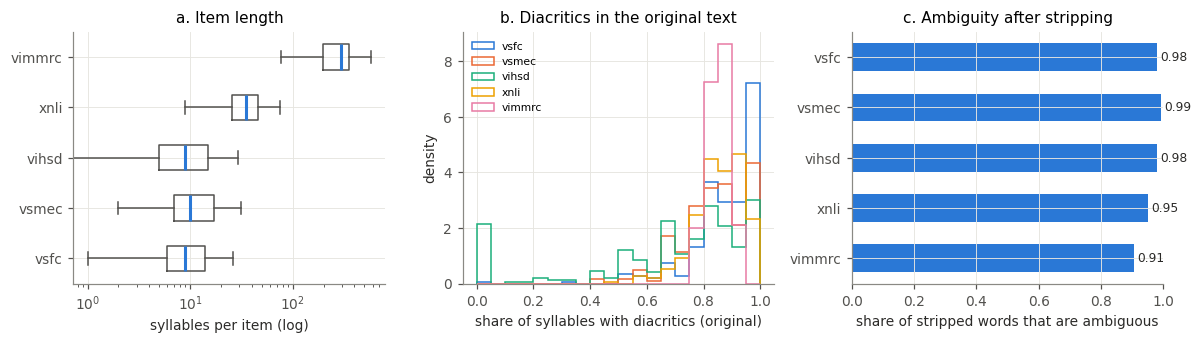

In [10]:
# Dataset figure: length, original accent share, ambiguity of stripped words
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
cl = pd.concat(DATA.values()).query("cond == 'clean'")
cl = cl.assign(syl=cl.clean.map(lambda s: len(syllable_spans(s))), acc=cl.clean.map(accent_share))
axes[0].boxplot([cl[cl.task == t].syl for t in TASKS], vert=False, widths=0.5, showfliers=False,
                medianprops=dict(color="#2a78d6", lw=2), boxprops=dict(color="#52514e"), whiskerprops=dict(color="#52514e"),
                capprops=dict(color="#52514e"))
axes[0].set(xscale="log", yticks=range(1, len(TASKS) + 1), yticklabels=TASKS, xlabel="syllables per item (log)",
            title="a. Item length")
for i, t in enumerate(TASKS):
    axes[1].hist(cl[cl.task == t].acc, bins=np.linspace(0, 1, 21), histtype="step", lw=2, color=PALETTE[i], label=t,
                 density=True)
axes[1].set(xlabel="share of syllables with diacritics (original)", ylabel="density", title="b. Diacritics in the original text")
axes[1].legend(fontsize=7)
s = FEAT[FEAT.cond == "strip"].groupby("task").amb_share.mean().reindex(TASKS)
axes[2].barh(range(len(TASKS)), s.values, color="#2a78d6", height=0.55)
for i, v in enumerate(s.values):
    axes[2].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8, color="#2b2a28")
axes[2].set(yticks=range(len(TASKS)), yticklabels=TASKS, xlim=(0, 1), xlabel="share of stripped words that are ambiguous",
            title="c. Ambiguity after stripping")
axes[2].invert_yaxis()
plt.tight_layout()
save(fig, "fig01_datasets")

In [11]:
# Paper tables: datasets, and one example in every condition
tab = data_audit[["sampled_items", "classes", "median_syllables", "accent_share_original", "share_items_without_diacritics"]].copy()
tab["chance"] = 1 / tab.classes
tab["ambiguous_when_stripped"] = FEAT[FEAT.cond == "strip"].groupby("task").amb_share.mean()
save_table(tab, "table_datasets", "Tasks used in the pilot (balanced test samples).")
ex = DATA["vsfc"][DATA["vsfc"].item_id == 7].set_index("cond").text.reindex(CONDITIONS).to_frame("VSFC item 7")
save_table(ex, "table_noise_examples", "One item under every noise condition.")
display(tab.round(2)); display(ex)

,sampled_items,classes,median_syllables,accent_share_original,share_items_without_diacritics,chance,ambiguous_when_stripped
task,,,,,,,
vsfc,300,3,9.0,0.88,0.0,0.33,0.98
vsmec,245,7,10.0,0.84,0.0,0.14,0.99
vihsd,300,3,9.0,0.68,0.1,0.33,0.98
xnli,300,3,35.0,0.86,0.0,0.33,0.95
vimmrc,160,4,292.5,0.86,0.0,0.25,0.91


,VSFC item 7
cond,
clean,tóm lại doubledot cô là giảng viên tệ nhất được học từ năm nhất đến bây giờ .
partial25,tóm lại doubledot co là giảng viên te nhất được học từ năm nhất den bay giờ .
partial50,tóm lại doubledot cô la giang viên te nhất duoc hoc từ nam nhất den bây gio .
partial75,tom lai doubledot co la giang vien te nhất được hoc tu nam nhất đến bay gio .
strip,tom lai doubledot co la giang vien te nhat duoc hoc tu nam nhat den bay gio .
teencode,tóm lại doubledot cô là gv tệ nhất dc học từ năm nhất đến bây h .
mixed,tóm lại doubledot co là gv te nhat dc hoc từ năm nhat den bây h .


## 2. Model output audit

Before any analysis: are the prediction files complete and internally consistent, do the stored predictions follow from the stored log-probabilities, and does every model see the same items with the same labels?

In [12]:
frames, issues = [], []
for m in MODELS:
    for t in TASKS:
        p = pred_path(m, t)
        if not os.path.exists(p):
            issues.append(f"missing: {SHORT[m]} / {t}")
            continue
        df = pd.read_csv(p)
        if "task" not in df:
            df.insert(0, "task", t)
        df["model"] = m  # v2 files may carry another spelling
        frames.append(df)
preds = pd.concat(frames, ignore_index=True)
K = {t: len(TASK_SPECS[t]["labels"]) for t in TASKS}
CHANCE = {t: 1 / K[t] for t in TASKS}

checks = []
for (m, t), g in preds.groupby(["model", "task"]):
    lp = g[[f"lp{k}" for k in range(K[t])]].to_numpy(float)
    n_items = DATA[t].item_id.nunique()
    # recompute raw and batch-calibrated predictions from the stored log-probs
    raw = lp.argmax(1)
    logp = lp - np.logaddexp.reduce(lp, axis=1, keepdims=True)
    cal = np.empty_like(logp)
    for c in CONDITIONS:
        i = (g.cond == c).to_numpy()
        cal[i] = logp[i] - np.log(np.exp(logp[i]).mean(0))
    truth = DATA[t][["item_id", "cond", "label"]]
    lab = g[["item_id", "cond", "label"]].merge(truth, on=["item_id", "cond"], how="left", suffixes=("", "_true"))
    checks.append({
        "model": SHORT[m], "task": t, "rows": len(g), "expected": n_items * len(CONDITIONS),
        "dup_rows": int(g.duplicated(["item_id", "cond"]).sum()),
        "lp_finite": bool(np.isfinite(lp).all()),
        "labels_match_data": bool((lab.label == lab.label_true).all()),
        "pred_raw_reproduced": (raw == g.pred_raw.to_numpy()).mean(),
        "pred_cal_reproduced": (cal.argmax(1) == g.pred.to_numpy()).mean(),
        "label_mass_reproduced": bool(np.allclose(np.exp(np.logaddexp.reduce(lp, axis=1)), g.label_mass, rtol=1e-3, atol=1e-6)),
        "nll_nonneg": bool((g.nll >= 0).all()), "items_zero_syllables": int((g.clean_syl == 0).sum() // len(CONDITIONS)),
    })
checks = pd.DataFrame(checks)
checks.to_csv(f"{OUT_DIR}/audit/output_integrity.csv", index=False)
problems = checks[(checks.rows != checks.expected) | (checks.dup_rows > 0) | ~checks.lp_finite | ~checks.labels_match_data
                  | (checks.pred_raw_reproduced < 0.999) | (checks.pred_cal_reproduced < 0.995) | ~checks.label_mass_reproduced
                  | ~checks.nll_nonneg]
print(f"{len(checks)} (model, task) files; missing: {issues or 'none'}")
print("files failing an integrity check:", "none" if problems.empty else "")
if not problems.empty:
    display(problems)
KEY["integrity_failures"] = len(problems)
KEY["model_task_files"] = len(checks)

80 (model, task) files; missing: none
files failing an integrity check: none


In [13]:
tok_items = pd.concat([pd.read_csv(f"{IN_DIR}/tokenizer/{m.replace('/', '__')}.csv") for m in MODELS])
tok_items = tok_items[tok_items.task.isin(TASKS)]
# clean_syl must be the same in the predictions, the tokenizer stats, and our rebuild
syl = pd.concat(DATA.values())[["task", "item_id", "cond", "clean"]]
syl["clean_syl_rebuilt"] = syl.clean.map(lambda s: len(syllable_spans(s)))
c1 = preds.merge(syl[["task", "item_id", "cond", "clean_syl_rebuilt"]], on=["task", "item_id", "cond"])
c2 = tok_items.merge(syl[["task", "item_id", "cond", "clean_syl_rebuilt"]], on=["task", "item_id", "cond"])
print("clean_syl consistent — predictions:", (c1.clean_syl == c1.clean_syl_rebuilt).mean(),
      "| tokenizer stats:", (c2.clean_syl == c2.clean_syl_rebuilt).mean())
print("tokenizer rows per model:", tok_items.groupby("model").size().unique())

# Which models share a tokenizer? Identical token counts on every (task, item, condition).
sig = tok_items.sort_values(["task", "item_id", "cond"]).groupby("model").n_tok.apply(lambda s: hash(tuple(s)))
TOK_CLASS = {m: f"tok{i}" for i, (_, ms) in enumerate(sig.groupby(sig)) for m in ms.index}
classes = pd.Series(TOK_CLASS).groupby(pd.Series(TOK_CLASS)).apply(lambda s: [SHORT[m] for m in s.index])
print("models with identical tokenization:"); [print("  ", v) for v in classes if len(v) > 1]

clean_syl consistent — predictions: 1.0 | tokenizer stats: 1.0
tokenizer rows per model: [9135]
models with identical tokenization:
   ['Qwen2.5-1.5B', 'Qwen2.5-3B', 'Qwen2.5-7B', 'Qwen3-1.7B', 'Qwen3-4B', 'Qwen3-8B', 'SeaLLMs-v3-1.5B', 'SeaLLMs-v3-7B']
   ['bloomz-1b7', 'bloomz-3b', 'bloomz-7b1']
   ['vinallama-2.7b', 'vinallama-7b']


[None, None, None]

In [14]:
preds["family"] = preds.model.map(lambda m: MODEL_INFO[m][0])
preds["size"] = preds.model.map(lambda m: MODEL_INFO[m][1])
preds["correct"] = (preds.pred == preds.label).astype(int)
preds["correct_raw"] = (preds.pred_raw == preds.label).astype(int)

clean = preds[preds.cond == "clean"]
mass = clean.groupby(["model", "task"]).label_mass.median().unstack().reindex(index=MODELS, columns=TASKS)
acc_clean = clean.groupby(["model", "task"]).correct.mean().unstack().reindex(index=MODELS, columns=TASKS)
gated = acc_clean.sub(pd.Series(CHANCE)) >= MIN_ABOVE_CHANCE
reliable = gated & (mass >= MIN_LABEL_MASS)
TIER = {}
for m in MODELS:
    for t in TASKS:
        TIER[(m, t)] = "reliable" if reliable.loc[m, t] else ("gated" if gated.loc[m, t] else "below gate")
preds["tier"] = [TIER[(m, t)] for m, t in zip(preds.model, preds.task)]
tiers = pd.Series(TIER).value_counts()
print("(model, task) pairs by tier:", tiers.to_dict())
KEY["tiers"] = tiers.to_dict()
print("\nGated but unreliable (label mass < 50%):", [f"{SHORT[m]}/{t}" for (m, t), v in TIER.items() if v == "gated"])

(model, task) pairs by tier: {'reliable': 52, 'gated': 19, 'below gate': 9}

Gated but unreliable (label mass < 50%): ['Qwen3-1.7B/vsfc', 'Qwen3-1.7B/vsmec', 'Qwen3-1.7B/vimmrc', 'Qwen3-4B/vihsd', 'Qwen3-4B/xnli', 'Qwen3-4B/vimmrc', 'Qwen3-8B/vsfc', 'Qwen3-8B/vsmec', 'Qwen3-8B/vihsd', 'Qwen3-8B/xnli', 'Qwen3-8B/vimmrc', 'vinallama-2.7b/xnli', 'bloomz-1b7/vsfc', 'bloomz-1b7/vsmec', 'bloomz-1b7/xnli', 'bloomz-3b/vsfc', 'bloomz-3b/vsmec', 'bloomz-7b1/vsfc', 'bloomz-7b1/xnli']


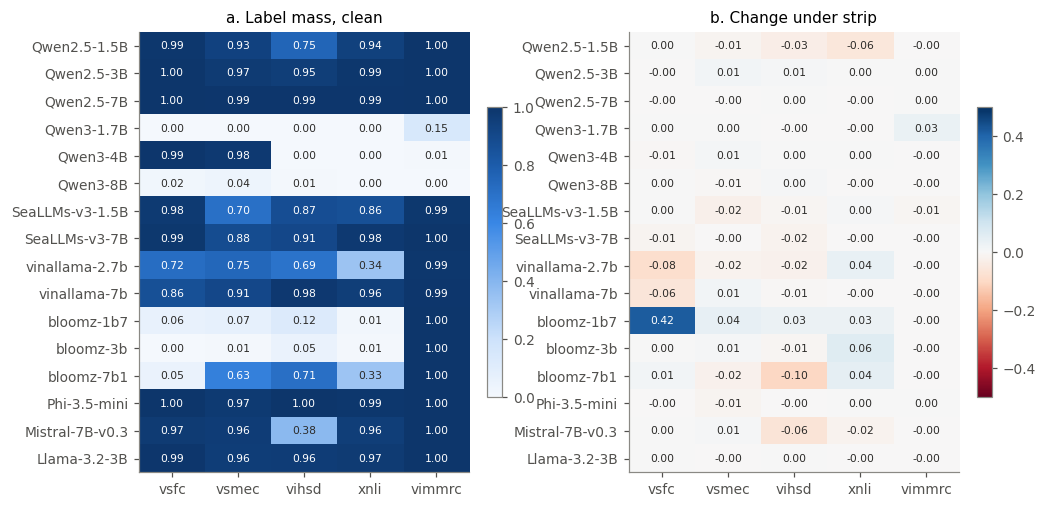

In [15]:
# Label mass: on clean text, and how it changes under strip (if noise moves probability away from the labels,
# part of the "drop" would be a format change rather than a judgement change)
mass_strip = preds[preds.cond == "strip"].groupby(["model", "task"]).label_mass.median().unstack().reindex(index=MODELS, columns=TASKS)
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw=dict(wspace=0.35))
for ax, M, title in [(axes[0], mass, "a. Label mass, clean"), (axes[1], mass_strip - mass, "b. Change under strip")]:
    if ax is axes[0]:
        im = ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    else:
        im = ax.imshow(M.values, cmap="RdBu", vmin=-0.5, vmax=0.5, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if np.isfinite(v):
                dark = (ax is axes[0] and v > 0.6) or (ax is axes[1] and abs(v) > 0.3)
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if dark else "#2b2a28")
    ax.set(xticks=range(len(TASKS)), xticklabels=TASKS, yticks=range(len(MODELS)), yticklabels=[SHORT[m] for m in MODELS], title=title)
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.04)
save(fig, "fig02_label_mass")

(model, task, condition) where >80% of RAW predictions are one label: 93
model            task 
Llama-3.2-3B     vsfc                                 [mixed, partial50, partial75, strip]
                 xnli                      [mixed, partial25, partial50, partial75, strip]
Mistral-7B-v0.3  xnli                      [mixed, partial25, partial50, partial75, strip]
Qwen2.5-1.5B     vihsd                                                             [strip]
                 vsfc                                                              [strip]
Qwen3-1.7B       xnli     [clean, mixed, partial25, partial50, partial75, strip, teencode]
SeaLLMs-v3-1.5B  vsfc            [mixed, partial25, partial50, partial75, strip, teencode]
                 vsmec    [clean, mixed, partial25, partial50, partial75, strip, teencode]
                 xnli            [mixed, partial25, partial50, partial75, strip, teencode]
SeaLLMs-v3-7B    xnli                      [mixed, partial25, partial50, partial75, s

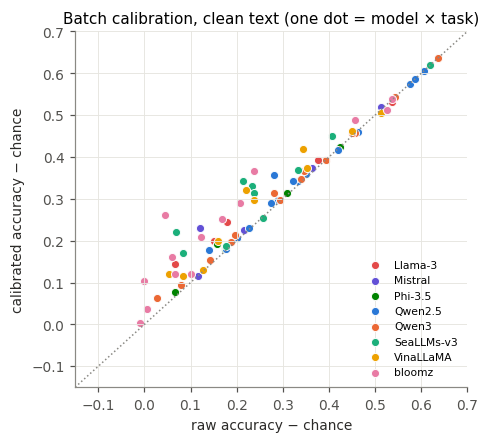

calibration helps on 0.78 of pairs; mean gain 0.034


In [16]:
# Does a model collapse onto one label? Share of the most frequent prediction, raw and calibrated, by condition
def top_share(s):
    return s.value_counts(normalize=True).iloc[0]
col = preds.groupby(["model", "task", "cond"]).agg(top_raw=("pred_raw", top_share), top_cal=("pred", top_share),
                                                   acc=("correct", "mean"), acc_raw=("correct_raw", "mean")).reset_index()
col["chance"] = col.task.map(CHANCE)
collapsed = col[(col.top_raw > 0.8)]
print("(model, task, condition) where >80% of RAW predictions are one label:", len(collapsed))
print(collapsed.assign(model=collapsed.model.map(SHORT)).groupby(["model", "task"]).cond.apply(list).to_string())
print("\nwhere >60% of CALIBRATED predictions are one label:", (col.top_cal > 0.6).sum())
col.to_csv(f"{OUT_DIR}/audit/prediction_collapse.csv", index=False)

# raw vs calibrated accuracy on clean text
cc = col[col.cond == "clean"]
fig, ax = plt.subplots(figsize=(4.6, 4.2))
for fam, g in cc.groupby(cc.model.map(lambda m: MODEL_INFO[m][0])):
    ax.scatter(g.acc_raw - g.chance, g.acc - g.chance, s=28, color=FAM_COLOR[fam], label=fam, edgecolor="white", lw=0.6)
lim = [-0.15, 0.7]
ax.plot(lim, lim, color="#8a8984", lw=1, ls=":")
ax.set(xlim=lim, ylim=lim, xlabel="raw accuracy − chance", ylabel="calibrated accuracy − chance",
       title="Batch calibration, clean text (one dot = model × task)")
ax.legend(fontsize=7, loc="lower right")
save(fig, "fig03_raw_vs_calibrated")
print("calibration helps on", (cc.acc > cc.acc_raw).mean().round(2), "of pairs; mean gain", (cc.acc - cc.acc_raw).mean().round(3))

In [17]:
# Free (greedy) answers from diagnostics.csv: what format does each model use, and does its free answer agree with the scored label?
diag = pd.read_csv(f"{IN_DIR}/diagnostics.csv", keep_default_na=False)
diag = diag[diag.model.isin(MODELS) & diag.task.isin(TASKS)].drop_duplicates(["model", "task", "item_id"], keep="last")
EN = r"\b(negative|positive|neutral|yes|no|true|false|entail|contradict|joy|sad|anger|fear|disgust|surprise|hate|offensive|clean|normal)"

def norm(s):
    return re.sub(r"[^\w\s]", " ", s.lower()).split()

def answer_format(task, ans):
    a = ans.strip()
    labels = TASK_SPECS[task]["labels"]
    if not a:
        return "empty"
    w = " ".join(norm(a))
    if task == "vimmrc":
        return "letter first" if re.match(r"^\W*[ABCD]\b", a) else "other"
    if w in labels:
        return "exact label"
    if "**" in a and any(l in w for l in labels):
        return "markdown"
    if any(w.startswith(l) for l in labels):
        return "label + more"
    if any(l in w for l in labels):
        return "label in sentence"
    if re.search(EN, a.lower()):
        return "English"
    return "other"

def parse_label(task, ans):
    w = " ".join(norm(ans))
    labels = TASK_SPECS[task]["labels"]
    if task == "vimmrc":
        m = re.match(r"^\W*([ABCD])\b", ans.strip())
        return "ABCD".index(m.group(1)) if m else np.nan
    hits = [(w.find(l), k) for k, l in enumerate(labels) if l in w]
    return min(hits)[1] if hits else np.nan

diag["format"] = [answer_format(t, a) for t, a in zip(diag.task, diag.answer)]
diag["free_label"] = [parse_label(t, a) for t, a in zip(diag.task, diag.answer)]
sc = clean[["model", "task", "item_id", "pred", "pred_raw", "label"]]
diag = diag.drop(columns=["label"], errors="ignore").merge(sc, on=["model", "task", "item_id"], how="left")
fmt = pd.crosstab(diag.model.map(SHORT), diag.format).reindex([SHORT[m] for m in MODELS])
print("Free-answer format, 6 probes per (model, task) on clean text:")
display(fmt.fillna(0).astype(int))
agree = diag.dropna(subset=["free_label"]).assign(agree=lambda d: d.free_label == d.pred_raw)
print("when the free answer names a label, it matches the scored (raw) label:", f"{agree.agree.mean():.0%}",
      f"of {len(agree)} probes")
display(agree.groupby(agree.model.map(SHORT)).agree.mean().reindex([SHORT[m] for m in MODELS]).round(2).to_frame("agreement").T)
diag.to_csv(f"{OUT_DIR}/audit/diagnostics_classified.csv", index=False)
KEY["free_vs_scored_agreement"] = round(float(agree.agree.mean()), 3)

Free-answer format, 6 probes per (model, task) on clean text:


format,English,empty,exact label,label + more,label in sentence,letter first,markdown,other
model,,,,,,,,
Qwen2.5-1.5B,0,0,9,0,5,4,0,1
Qwen2.5-3B,0,0,11,3,0,4,0,1
Qwen2.5-7B,0,0,12,0,0,4,0,0
Qwen3-1.7B,0,0,0,2,0,4,9,4
Qwen3-4B,0,0,6,0,0,4,8,1
Qwen3-8B,0,0,9,0,0,4,3,0
SeaLLMs-v3-1.5B,0,0,6,0,8,4,0,1
SeaLLMs-v3-7B,0,0,10,0,0,0,0,6
vinallama-2.7b,0,0,0,0,7,0,0,12


when the free answer names a label, it matches the scored (raw) label: 72% of 211 probes


model,Qwen2.5-1.5B,Qwen2.5-3B,Qwen2.5-7B,Qwen3-1.7B,Qwen3-4B,Qwen3-8B,SeaLLMs-v3-1.5B,SeaLLMs-v3-7B,vinallama-2.7b,vinallama-7b,bloomz-1b7,bloomz-3b,bloomz-7b1,Phi-3.5-mini,Mistral-7B-v0.3,Llama-3.2-3B
agreement,0.67,0.67,0.88,0.53,0.83,0.75,0.72,0.5,0.57,0.47,1.0,1.0,1.0,0.83,0.9,0.68


## 3. Model-level results (corrected)

`norm_drop` = (clean acc − noisy acc) ÷ (clean acc − chance), with **paired bootstrap CIs**: the same item resamples are used for every model of a task, so differences between models (e.g. small vs large in one family) get valid CIs too.

In [18]:
rng = np.random.default_rng(SEED)
IDX = {t: rng.integers(0, DATA[t].item_id.nunique(), (B, DATA[t].item_id.nunique())) for t in TASKS}
CHANGED = FEAT.pivot_table(index=["task", "item_id"], columns="cond", values="changed")

def ci(a):
    return np.nanpercentile(a, 2.5), np.nanpercentile(a, 97.5)

rows, BOOT = [], {}
for (m, t), g in preds.groupby(["model", "task"]):
    Cm = g.pivot(index="item_id", columns="cond", values="correct").sort_index()[CONDITIONS].to_numpy(float)
    ch = CHANCE[t]
    bs = Cm[IDX[t]].mean(1)  # (B, conditions)
    nll = g.pivot(index="item_id", columns="cond", values="nll").sort_index()[CONDITIONS]
    syl = g.pivot(index="item_id", columns="cond", values="clean_syl").sort_index()["clean"]
    nll_syl = nll.sum() / syl.sum()
    for j, c in enumerate(CONDITIONS):
        clean_acc, acc = Cm[:, 0].mean(), Cm[:, j].mean()
        above = clean_acc - ch
        nd_b = (bs[:, 0] - bs[:, j]) / np.where(bs[:, 0] - ch > 0.05, bs[:, 0] - ch, np.nan)
        BOOT[(m, t, c)] = nd_b
        changed = CHANGED.loc[t][c].sort_index().to_numpy() > 0
        acc_ch = Cm[changed, j].mean() if changed.any() else np.nan
        clean_ch = Cm[changed, 0].mean() if changed.any() else np.nan
        lo, hi = ci(nd_b)
        rows.append({"model": m, "task": t, "cond": c, "family": MODEL_INFO[m][0], "size": MODEL_INFO[m][1],
                     "tier": TIER[(m, t)], "acc": acc, "acc_raw": g[g.cond == c].correct_raw.mean(),
                     "drop": clean_acc - acc,
                     "norm_drop": (clean_acc - acc) / above if above > 0.05 else np.nan, "nd_lo": lo, "nd_hi": hi,
                     "norm_drop_changed_only": (clean_ch - acc_ch) / (clean_ch - ch) if clean_ch - ch > 0.05 else np.nan,
                     "label_mass": g[g.cond == c].label_mass.median(),
                     "ppl_ratio": np.exp(nll_syl[c] - nll_syl["clean"])})
S = pd.DataFrame(rows)
g = tok_items.groupby(["model", "task", "cond"]).sum(numeric_only=True)
ts = pd.DataFrame({"fertility": g.n_tok / g.clean_syl, "broken_rate": g.n_broken / g.n_syl,
                   "fragment_rate": g.n_frag / g.n_tok}).reset_index()
S = S.merge(ts, on=["model", "task", "cond"], how="left")
for k in ["fertility", "broken_rate", "fragment_rate"]:
    base = S[S.cond == "clean"].set_index(["model", "task"])[k]
    S[f"d_{k}"] = S[k].to_numpy() - base.loc[list(zip(S.model, S.task))].to_numpy()
S.to_csv(f"{OUT_DIR}/tables/summary_v22.csv", index=False)
print(len(S), "rows")

560 rows


In [19]:
# Main table: norm_drop under strip with 95% CI; † = gated but label mass < 50%; blank = below gate
def cell(r):
    if r.tier == "below gate" or not np.isfinite(r.norm_drop):
        return ""
    return f"{r.norm_drop:.2f} [{r.nd_lo:.2f}, {r.nd_hi:.2f}]" + ("†" if r.tier == "gated" else "")
st = S[S.cond == "strip"]
tab = st.assign(v=[cell(r) for r in st.itertuples()]).pivot(index="model", columns="task", values="v").reindex(index=MODELS, columns=TASKS)
tab.index = [SHORT[m] for m in MODELS]
acc_tab = S[S.cond == "clean"].pivot(index="model", columns="task", values="acc").reindex(index=MODELS, columns=TASKS)
acc_tab.index = tab.index
save_table(acc_tab, "table_clean_accuracy", "Clean accuracy (batch-calibrated).")
save_table(tab, "table_normdrop_strip", "Normalised drop under full diacritic removal, 95% paired bootstrap CI. † label mass < 50%.")
display(acc_tab.round(2)); display(tab)

task,vsfc,vsmec,vihsd,xnli,vimmrc
Qwen2.5-1.5B,0.69,0.44,0.51,0.54,0.82
Qwen2.5-3B,0.79,0.43,0.51,0.68,0.84
Qwen2.5-7B,0.75,0.49,0.56,0.69,0.86
Qwen3-1.7B,0.73,0.30,0.43,0.40,0.79
Qwen3-4B,0.79,0.44,0.55,0.68,0.89
Qwen3-8B,0.79,0.51,0.53,0.65,0.89
SeaLLMs-v3-1.5B,0.66,0.36,0.52,0.50,0.70
SeaLLMs-v3-7B,0.70,0.46,0.59,0.68,0.87
vinallama-2.7b,0.65,0.34,0.45,0.45,0.67
vinallama-7b,0.80,0.44,0.46,0.71,0.76


task,vsfc,vsmec,vihsd,xnli,vimmrc
Qwen2.5-1.5B,"0.73 [0.59, 0.88]","0.59 [0.41, 0.77]","0.79 [0.51, 1.09]","0.45 [0.18, 0.71]","0.37 [0.24, 0.49]"
Qwen2.5-3B,"0.36 [0.25, 0.47]","0.63 [0.45, 0.80]","0.31 [0.00, 0.58]","0.38 [0.23, 0.53]","0.31 [0.19, 0.43]"
Qwen2.5-7B,"0.21 [0.10, 0.31]","0.42 [0.27, 0.56]","0.36 [0.15, 0.56]","0.21 [0.07, 0.36]","0.24 [0.13, 0.35]"
Qwen3-1.7B,"0.55 [0.41, 0.69]†","0.47 [0.09, 0.78]†",,,"0.32 [0.18, 0.45]†"
Qwen3-4B,"0.31 [0.22, 0.41]","0.44 [0.27, 0.61]","0.39 [0.16, 0.60]†","0.26 [0.12, 0.40]†","0.16 [0.06, 0.26]†"
Qwen3-8B,"0.17 [0.08, 0.25]†","0.54 [0.41, 0.68]†","0.34 [0.04, 0.60]†","0.33 [0.20, 0.46]†","0.09 [-0.01, 0.18]†"
SeaLLMs-v3-1.5B,"0.74 [0.57, 0.90]","0.56 [0.30, 0.78]","0.50 [0.18, 0.79]","0.69 [0.35, 1.02]","0.26 [0.09, 0.42]"
SeaLLMs-v3-7B,"0.35 [0.22, 0.49]","0.57 [0.40, 0.73]","0.33 [0.09, 0.54]","0.34 [0.18, 0.50]","0.21 [0.10, 0.32]"
vinallama-2.7b,"0.64 [0.47, 0.80]","0.47 [0.19, 0.71]",,"0.69 [0.20, 1.16]†","0.42 [0.20, 0.61]"
vinallama-7b,"0.68 [0.56, 0.81]","0.77 [0.59, 0.93]","0.28 [-0.13, 0.62]","0.71 [0.57, 0.87]","0.47 [0.30, 0.61]"


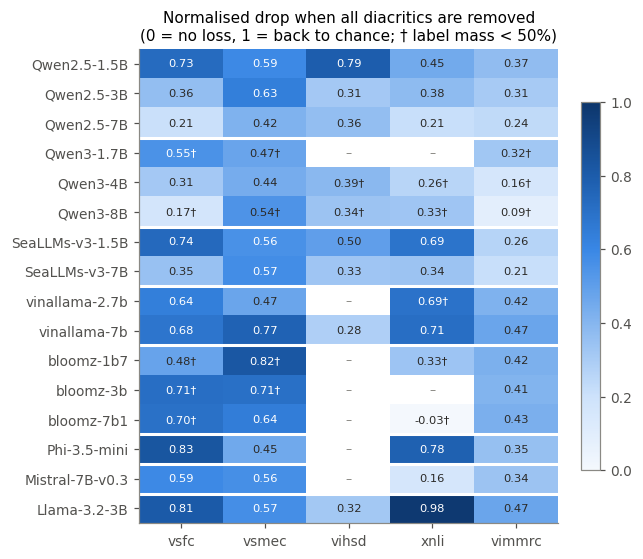

In [20]:
# Heatmap of norm_drop (strip) — † = gated but unreliable, blank = below gate
M = st.pivot(index="model", columns="task", values="norm_drop").reindex(index=MODELS, columns=TASKS)
T = st.pivot(index="model", columns="task", values="tier").reindex(index=MODELS, columns=TASKS)
M = M.where(T != "below gate")
fig, ax = plt.subplots(figsize=(5.4, 5.6))
im = ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v, tier = M.values[i, j], T.values[i, j]
        if tier == "below gate":
            ax.text(j, i, "–", ha="center", va="center", color="#8a8984", fontsize=8)
        elif np.isfinite(v):
            ax.text(j, i, f"{v:.2f}" + ("†" if tier == "gated" else ""), ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.55 else "#2b2a28")
ax.set(xticks=range(len(TASKS)), xticklabels=TASKS, yticks=range(len(MODELS)), yticklabels=[SHORT[m] for m in MODELS],
       title="Normalised drop when all diacritics are removed\n(0 = no loss, 1 = back to chance; † label mass < 50%)")
ax.grid(False)
for i in range(1, len(MODELS)):
    if MODEL_INFO[MODELS[i]][0] != MODEL_INFO[MODELS[i - 1]][0]:
        ax.axhline(i - 0.5, color="white", lw=2)
plt.colorbar(im, ax=ax, fraction=0.04)
save(fig, "fig04_normdrop_heatmap")

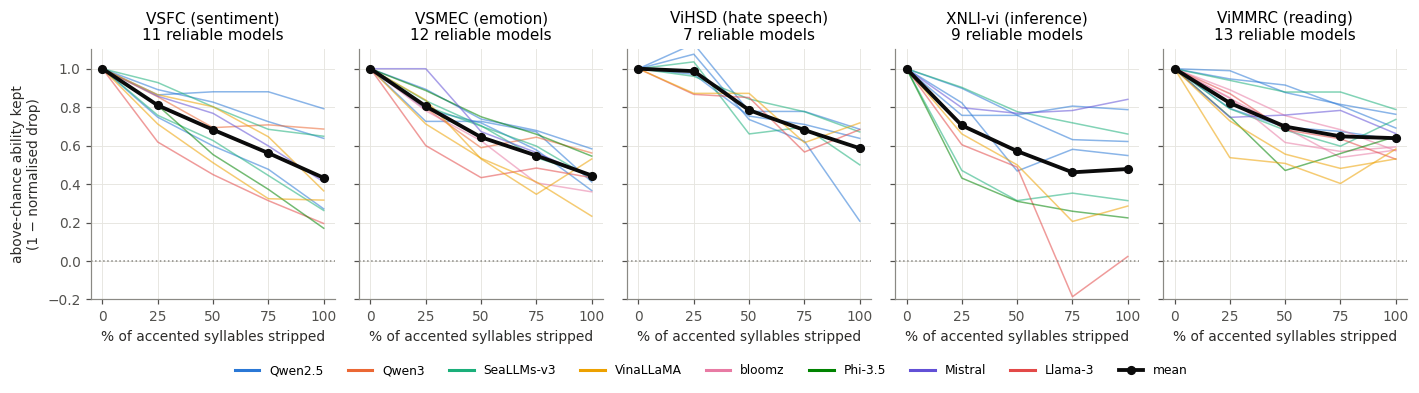

monotone (allowing 0.03 noise) for 63% of reliable (model, task) pairs


In [21]:
# Dose-response: accuracy (as share of the above-chance ability kept) vs share of diacritics removed
fig, axes = plt.subplots(1, len(TASKS), figsize=(13, 3.3), sharey=True)
dr = S[S.cond.isin(LEVEL) & (S.tier == "reliable")].copy()
dr["level"] = dr.cond.map(LEVEL)
dr["kept"] = 1 - dr.norm_drop.fillna(0)
dose = {}
for ax, t in zip(axes, TASKS):
    g = dr[dr.task == t]
    for m, gm in g.groupby("model"):
        gm = gm.sort_values("level")
        ax.plot(gm.level, gm.kept, color=FAM_COLOR[MODEL_INFO[m][0]], lw=1, alpha=0.55)
    mean = g.groupby("level").kept.mean()
    ax.plot(mean.index, mean.values, color="#0b0b0b", lw=2.5, marker="o", label="mean")
    dose[t] = mean.round(3).to_dict()
    ax.set(title=f"{TASK_NAME[t]}\n{g.model.nunique()} reliable models", xlabel="% of accented syllables stripped",
           xticks=[0, 25, 50, 75, 100], ylim=(-0.2, 1.1))
    ax.axhline(0, color="#8a8984", lw=1, ls=":")
axes[0].set_ylabel("above-chance ability kept\n(1 − normalised drop)")
handles = [plt.Line2D([], [], color=FAM_COLOR[f], lw=2) for f in FAMILIES if f in set(dr.family)]
fig.legend(handles + [plt.Line2D([], [], color="#0b0b0b", lw=2.5, marker="o")],
           [f for f in FAMILIES if f in set(dr.family)] + ["mean"], loc="lower center", ncol=9, fontsize=8, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
save(fig, "fig05_dose_response")
KEY["dose_response_kept_mean"] = dose

# Is the dose-response monotone for each reliable model?
mono = dr.sort_values("level").groupby(["model", "task"]).kept.apply(lambda s: bool((np.diff(s.values) <= 0.03).all()))
print(f"monotone (allowing 0.03 noise) for {mono.mean():.0%} of reliable (model, task) pairs")
KEY["dose_monotone_share"] = round(float(mono.mean()), 3)

In [22]:
# Mean norm_drop by task × condition, gated vs reliable tiers
for tier, sel in [("gated (incl. reliable)", S.tier != "below gate"), ("reliable only", S.tier == "reliable")]:
    print("mean normalised drop —", tier)
    display(S[sel & (S.cond != "clean")].pivot_table(index="task", columns="cond", values="norm_drop", aggfunc="mean")
            .reindex(index=TASKS, columns=NOISY).round(2))
KEY["mean_normdrop_strip_reliable"] = S[(S.tier == "reliable") & (S.cond == "strip")].groupby("task").norm_drop.mean().round(3).to_dict()
KEY["mean_normdrop_teencode_reliable"] = S[(S.tier == "reliable") & (S.cond == "teencode")].groupby("task").norm_drop.mean().round(3).to_dict()
print("ViHSD strip, changed items only vs all items (gated):")
display(S[(S.task == "vihsd") & (S.cond == "strip") & (S.tier != "below gate")].assign(model=lambda d: d.model.map(SHORT))
        [["model", "norm_drop", "norm_drop_changed_only"]].round(2).set_index("model").T)

mean normalised drop — gated (incl. reliable)


cond,partial25,partial50,partial75,strip,teencode,mixed
task,,,,,,
vsfc,0.18,0.32,0.45,0.55,0.05,0.34
vsmec,0.20,0.34,0.45,0.58,0.02,0.35
vihsd,0.02,0.21,0.31,0.40,0.03,0.16
xnli,0.28,0.34,0.45,0.45,0.11,0.34
vimmrc,0.15,0.27,0.31,0.33,0.02,0.30


mean normalised drop — reliable only


cond,partial25,partial50,partial75,strip,teencode,mixed
task,,,,,,
vsfc,0.19,0.32,0.44,0.57,0.07,0.37
vsmec,0.20,0.36,0.45,0.56,0.02,0.35
vihsd,0.01,0.22,0.32,0.41,0.03,0.15
xnli,0.29,0.43,0.54,0.52,0.10,0.44
vimmrc,0.18,0.30,0.35,0.36,0.03,0.34


ViHSD strip, changed items only vs all items (gated):


model,Qwen2.5-1.5B,Qwen2.5-3B,Qwen2.5-7B,Qwen3-4B,Qwen3-8B,SeaLLMs-v3-1.5B,SeaLLMs-v3-7B,Llama-3.2-3B,vinallama-7b
norm_drop,0.79,0.31,0.36,0.39,0.34,0.50,0.33,0.32,0.28
norm_drop_changed_only,0.94,0.35,0.42,0.43,0.38,0.54,0.33,0.34,0.33


### Scale within a family (tokenizer fixed), with CIs

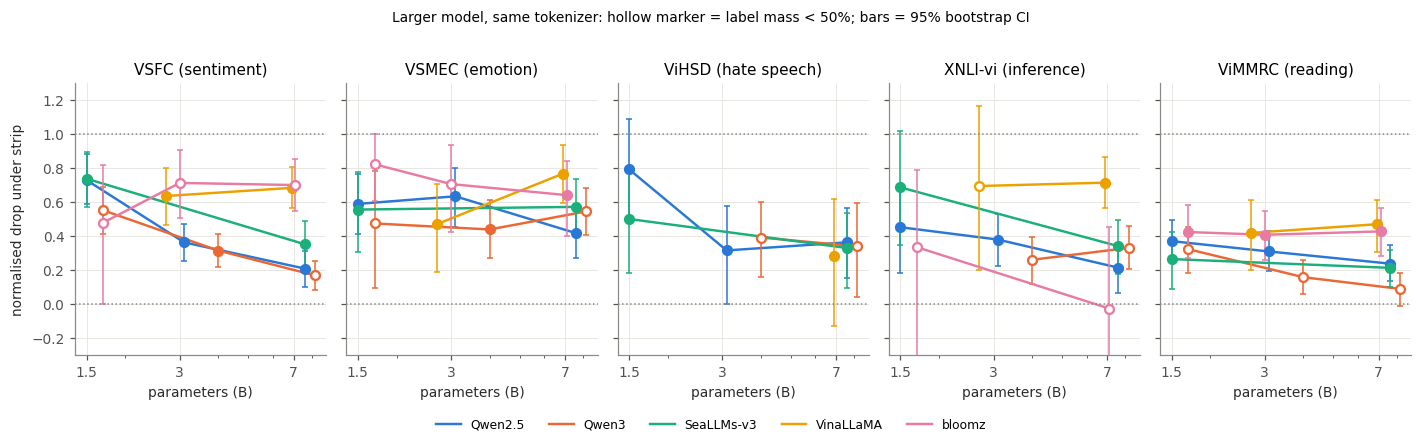

,task,family,small,large,nd_small,nd_large,diff,lo,hi,both_reliable,sig
0,vsfc,Qwen2.5,Qwen2.5-1.5B,Qwen2.5-7B,0.73,0.21,0.52,0.35,0.69,True,True
1,vsfc,Qwen3,Qwen3-1.7B,Qwen3-8B,0.55,0.17,0.38,0.23,0.54,False,True
2,vsfc,SeaLLMs-v3,SeaLLMs-v3-1.5B,SeaLLMs-v3-7B,0.74,0.35,0.39,0.18,0.59,True,True
3,vsfc,VinaLLaMA,vinallama-2.7b,vinallama-7b,0.64,0.68,-0.05,-0.23,0.12,True,False
4,vsfc,bloomz,bloomz-1b7,bloomz-7b1,0.48,0.70,-0.22,-0.72,0.17,False,False
5,vsmec,Qwen2.5,Qwen2.5-1.5B,Qwen2.5-7B,0.59,0.42,0.17,-0.02,0.36,True,False
6,vsmec,Qwen3,Qwen3-1.7B,Qwen3-8B,0.47,0.54,-0.07,-0.46,0.25,False,False
7,vsmec,SeaLLMs-v3,SeaLLMs-v3-1.5B,SeaLLMs-v3-7B,0.56,0.57,-0.02,-0.26,0.21,True,False
8,vsmec,VinaLLaMA,vinallama-2.7b,vinallama-7b,0.47,0.77,-0.30,-0.60,-0.04,True,True
9,vsmec,bloomz,bloomz-1b7,bloomz-7b1,0.82,0.64,0.18,-0.10,0.48,False,False


In [23]:
fam_multi = [f for f in FAMILIES if S[S.family == f]["size"].nunique() > 1]
fig, axes = plt.subplots(1, len(TASKS), figsize=(13, 3.6), sharey=True)
diff_rows = []
for ax, t in zip(axes, TASKS):
    for f in fam_multi:
        g = st[(st.task == t) & (st.family == f) & (st.tier != "below gate")].sort_values("size")
        if g.empty:
            continue
        x = g["size"].to_numpy()
        ax.plot(x, g.norm_drop, color=FAM_COLOR[f], lw=1.6, label=f)
        ax.errorbar(x, g.norm_drop, yerr=[g.norm_drop - g.nd_lo, g.nd_hi - g.norm_drop], fmt="none", ecolor=FAM_COLOR[f],
                    elinewidth=1, capsize=2)
        for r in g.itertuples():
            ax.scatter(r.size, r.norm_drop, s=34, zorder=3, color=FAM_COLOR[f] if r.tier == "reliable" else "white",
                       edgecolor=FAM_COLOR[f], lw=1.5)
        if len(g) >= 2:
            small, large = g.iloc[0].model, g.iloc[-1].model
            d = BOOT[(small, t, "strip")] - BOOT[(large, t, "strip")]
            lo, hi = ci(d)
            diff_rows.append({"task": t, "family": f, "small": SHORT[small], "large": SHORT[large],
                              "nd_small": g.iloc[0].norm_drop, "nd_large": g.iloc[-1].norm_drop,
                              "diff": g.iloc[0].norm_drop - g.iloc[-1].norm_drop, "lo": lo, "hi": hi,
                              "both_reliable": bool((g.iloc[[0, -1]].tier == "reliable").all())})
    ax.set(title=TASK_NAME[t], xlabel="parameters (B)", xscale="log", ylim=(-0.3, 1.3))
    ax.set_xticks([1.5, 3, 7], ["1.5", "3", "7"])
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.axhline(1, color="#8a8984", lw=1, ls=":")
    ax.axhline(0, color="#8a8984", lw=1, ls=":")
axes[0].set_ylabel("normalised drop under strip")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(l), fontsize=8, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Larger model, same tokenizer: hollow marker = label mass < 50%; bars = 95% bootstrap CI", y=1.02, fontsize=9)
plt.tight_layout()
save(fig, "fig06_scale_by_family")
scale = pd.DataFrame(diff_rows)
scale["sig"] = (scale.lo > 0) | (scale.hi < 0)
save_table(scale.set_index(["family", "task"]), "table_scale_small_minus_large",
           "Normalised drop (strip), smallest minus largest model of a family; positive = larger model is more robust.")
display(scale.round(2))
KEY["scale_diffs"] = scale.round(3).to_dict("records")

In [24]:
# Matched pair: Qwen2.5-3B vs Llama-3.2-3B (similar size and similar Δfertility), and every same-size pair at ~7B
def pair_table(a, b):
    out = []
    for t in TASKS:
        if (a, t, "strip") not in BOOT or (b, t, "strip") not in BOOT:
            continue
        ra = st[(st.model == a) & (st.task == t)].iloc[0]
        rb = st[(st.model == b) & (st.task == t)].iloc[0]
        lo, hi = ci(BOOT[(b, t, "strip")] - BOOT[(a, t, "strip")])
        out.append({"task": t, SHORT[a]: ra.norm_drop, SHORT[b]: rb.norm_drop, "diff (b−a)": rb.norm_drop - ra.norm_drop,
                    "lo": lo, "hi": hi, "dfert_a": ra.d_fertility, "dfert_b": rb.d_fertility,
                    "tiers": f"{ra.tier}/{rb.tier}"})
    return pd.DataFrame(out).set_index("task")
if "meta-llama/Llama-3.2-3B-Instruct" in MODELS:
    pq = pair_table("Qwen/Qwen2.5-3B-Instruct", "meta-llama/Llama-3.2-3B-Instruct")
    save_table(pq, "table_pair_qwen3b_llama3b", "Qwen2.5-3B vs Llama-3.2-3B under strip.")
    display(pq.round(2))
    KEY["pair_qwen3b_llama3b"] = pq.round(3).reset_index().to_dict("records")

,Qwen2.5-3B,Llama-3.2-3B,diff (b−a),lo,hi,dfert_a,dfert_b,tiers
task,,,,,,,,
vsfc,0.36,0.81,0.44,0.28,0.60,0.31,0.24,reliable/reliable
vsmec,0.63,0.57,-0.07,-0.31,0.16,0.10,0.02,reliable/reliable
vihsd,0.31,0.32,0.00,-0.39,0.38,0.10,-0.02,reliable/reliable
xnli,0.38,0.98,0.60,0.21,1.14,0.27,0.22,reliable/reliable
vimmrc,0.31,0.47,0.16,-0.03,0.35,0.15,0.08,reliable/reliable


### Tokenizer vs exposure at model level — within each condition

Pooling all noise levels mixes "more noise" with "worse tokenizer". Here each condition is analysed on its own, then all together with condition and task fixed effects (SEs clustered by model).

In [25]:
gs = S[(S.tier != "below gate") & (S.cond != "clean")].dropna(subset=["norm_drop"]).copy()
gs["log_ppl"] = np.log(gs.ppl_ratio)
PRED_M = ["d_fertility", "d_broken_rate", "d_fragment_rate", "log_ppl"]
rows = []
for c in NOISY:
    g = gs[gs.cond == c]
    rows.append({"cond": c, "points": len(g), **{k: spearmanr(g[k], g.norm_drop)[0] for k in PRED_M}})
within = pd.DataFrame(rows).set_index("cond")
print("Spearman ρ with norm_drop, within each condition (pooled over tasks):")
display(within.round(2))
rows = []
for (c, t), g in gs.groupby(["cond", "task"]):
    if len(g) >= 6:
        rows.append({"cond": c, "task": t, "n": len(g), **{k: spearmanr(g[k], g.norm_drop)[0] for k in PRED_M}})
wt = pd.DataFrame(rows)
print("Average ρ within condition × task cells (each cell = one point per model):")
display(wt.groupby("cond")[PRED_M].mean().reindex(NOISY).round(2))
save_table(wt.set_index(["cond", "task"]), "table_model_level_rho_within", "Spearman ρ within condition × task.")

for k in ["d_fertility", "d_broken_rate", "log_ppl"]:
    gs[f"z_{k}"] = (gs[k] - gs[k].mean()) / gs[k].std()
f = smf.ols("norm_drop ~ z_d_fertility + z_d_broken_rate + z_log_ppl + C(cond) + C(task)", data=gs).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(gs.model)[0]})
ml = pd.DataFrame({"coef": f.params, "lo": f.conf_int()[0], "hi": f.conf_int()[1], "p": f.pvalues}).loc[
    ["z_d_fertility", "z_d_broken_rate", "z_log_ppl"]]
print(f"OLS on {len(gs)} (model, task, condition) points, condition + task FE, SE clustered by model:")
display(ml.round(3))
save_table(ml, "table_model_level_ols", "Model-level OLS, condition and task fixed effects.", "%.3f")
KEY["model_level_ols"] = ml.round(4).reset_index().to_dict("records")
KEY["rho_within_strip"] = within.loc["strip"].round(3).to_dict()

Spearman ρ with norm_drop, within each condition (pooled over tasks):


,points,d_fertility,d_broken_rate,d_fragment_rate,log_ppl
cond,,,,,
partial25,71,0.07,0.13,-0.08,0.39
partial50,71,-0.01,-0.05,-0.18,0.31
partial75,71,0.02,-0.06,-0.21,0.38
strip,71,-0.03,-0.08,-0.14,0.29
teencode,71,-0.05,0.05,0.08,0.22
mixed,71,-0.01,-0.01,-0.27,0.37


Average ρ within condition × task cells (each cell = one point per model):


,d_fertility,d_broken_rate,d_fragment_rate,log_ppl
cond,,,,
partial25,-0.13,-0.22,-0.34,0.26
partial50,0.18,0.10,-0.07,0.33
partial75,-0.09,-0.26,-0.40,0.44
strip,0.17,-0.07,-0.09,0.42
teencode,-0.08,0.12,-0.13,0.37
mixed,0.21,0.06,-0.38,0.45


OLS on 426 (model, task, condition) points, condition + task FE, SE clustered by model:


,coef,lo,hi,p
z_d_fertility,0.050,-0.072,0.172,0.423
z_d_broken_rate,-0.099,-0.233,0.034,0.144
z_log_ppl,0.123,0.055,0.191,0.000


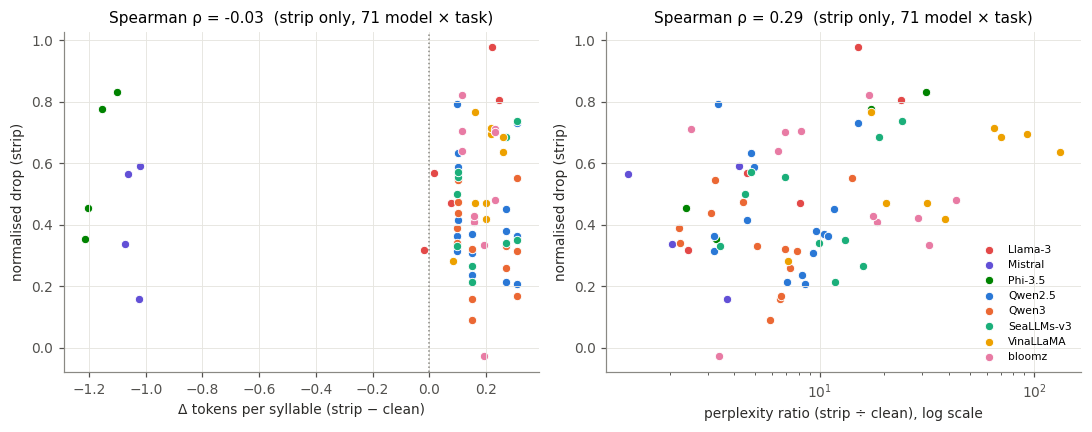

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
g = gs[gs.cond == "strip"]
for ax, k, lab in [(axes[0], "d_fertility", "Δ tokens per syllable (strip − clean)"),
                   (axes[1], "ppl_ratio", "perplexity ratio (strip ÷ clean), log scale")]:
    for fam, gf in g.groupby("family"):
        ax.scatter(gf[k], gf.norm_drop, s=30, color=FAM_COLOR[fam], label=fam, edgecolor="white", lw=0.6,
                   marker="o")
    r = spearmanr(g[k], g.norm_drop)[0]
    ax.set(xlabel=lab, ylabel="normalised drop (strip)", title=f"Spearman ρ = {r:.2f}  (strip only, {len(g)} model × task)")
axes[1].set_xscale("log")
axes[0].axvline(0, color="#8a8984", lw=1, ls=":")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
save(fig, "fig07_model_level_mechanism")

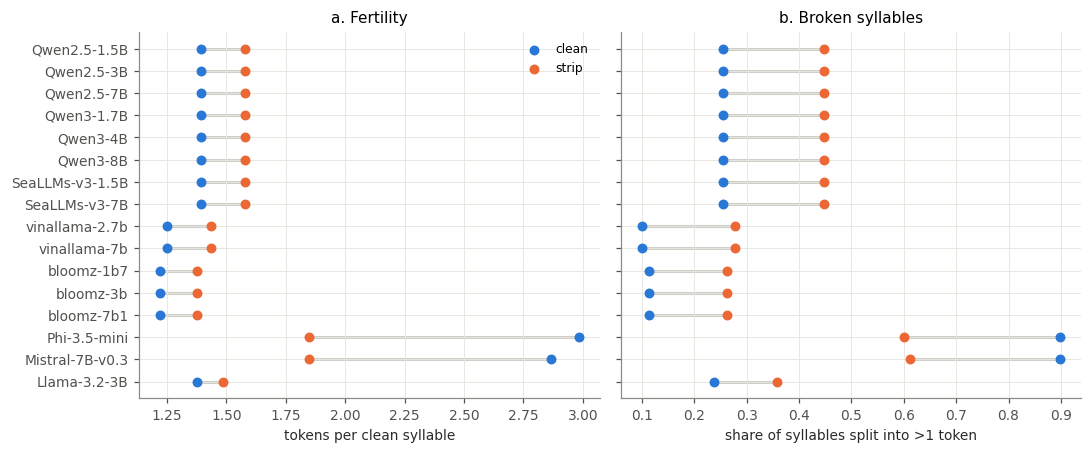

In [27]:
# Tokenizer behaviour: fertility clean vs strip per model (averaged over tasks)
fe = S[S.cond.isin(["clean", "strip"])].groupby(["model", "cond"]).fertility.mean().unstack().reindex(MODELS)
br = S[S.cond.isin(["clean", "strip"])].groupby(["model", "cond"]).broken_rate.mean().unstack().reindex(MODELS)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
y = np.arange(len(MODELS))
for ax, D, lab in [(axes[0], fe, "tokens per clean syllable"), (axes[1], br, "share of syllables split into >1 token")]:
    for i, m in enumerate(MODELS):
        ax.plot([D.loc[m, "clean"], D.loc[m, "strip"]], [i, i], color="#cfcec8", lw=2, zorder=1)
    ax.scatter(D["clean"], y, color="#2a78d6", s=30, zorder=2, label="clean")
    ax.scatter(D["strip"], y, color="#eb6834", s=30, zorder=2, label="strip")
    ax.set(xlabel=lab, yticks=y, yticklabels=[SHORT[m] for m in MODELS])
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
axes[0].set_title("a. Fertility")
axes[1].set_title("b. Broken syllables")
plt.tight_layout()
save(fig, "fig08_tokenizer")

## 4. Item-level analysis (corrected)

One row per (model, task, item, noisy condition) where the model was **right on the clean item** and the noise **changed** the item. Outcome: did it flip to wrong?

Predictors (z-scored): `d_tok` (extra tokens per syllable), **`d_broken`** (change in the share of broken syllables, new), `d_nll` (extra NLL per syllable: exposure), `log_len`, and for partial/strip **`amb_bits`** (mean log₂ number of accented forms behind each stripped word: how much information was destroyed). Fixed effects for model, task and condition; SEs clustered by item, **by article for ViMMRC and by premise for XNLI**.

In [28]:
it = preds.merge(tok_items, on=["model", "task", "item_id", "cond"], suffixes=("", "_tok")).merge(FEAT, on=["task", "item_id", "cond"])
it["nll_syl"] = it.nll / it.clean_syl.clip(lower=1)
it["broken_share"] = it.n_broken / it.n_syl.clip(lower=1)
base = it[it.cond == "clean"][["model", "task", "item_id", "correct", "n_tok", "nll_syl", "broken_share", "label_mass"]]
X = it[it.cond != "clean"].merge(base, on=["model", "task", "item_id"], suffixes=("", "_clean"))
X = X[(X.correct_clean == 1) & (X.changed > 0) & (X.tier != "below gate")].copy()
X["flip"] = 1 - X.correct
X = X[X.clean_syl > 0]
X["d_tok"] = (X.n_tok - X.n_tok_clean) / X.clean_syl
X["d_broken"] = X.broken_share - X.broken_share_clean
X["d_nll"] = X.nll_syl - X.nll_syl_clean
X["log_len"] = np.log(X.clean_syl)
TERMS = ["d_tok", "d_broken", "broken_share", "d_nll", "log_len", "amb_bits", "changed"]
for k in TERMS:
    X[f"z_{k}"] = (X[k] - X[k].mean()) / X[k].std()
X.to_csv(f"{OUT_DIR}/tables/item_level_v22.csv.gz", index=False)
print(f"{len(X)} rows, flip rate {X.flip.mean():.3f}; reliable rows {(X.tier == 'reliable').sum()}")
print("predictor correlations:")
display(X[["d_tok", "d_broken", "broken_share", "d_nll", "log_len", "amb_bits", "changed"]].corr().round(2))

60992 rows, flip rate 0.274; reliable rows 44478
predictor correlations:


,d_tok,d_broken,broken_share,d_nll,log_len,amb_bits,changed
d_tok,1.00,0.86,-0.25,0.19,0.01,-0.10,0.04
d_broken,0.86,1.00,0.03,0.29,-0.02,-0.17,0.24
broken_share,-0.25,0.03,1.00,-0.01,0.09,-0.21,0.18
d_nll,0.19,0.29,-0.01,1.00,-0.13,-0.10,0.32
log_len,0.01,-0.02,0.09,-0.13,1.00,-0.11,-0.02
amb_bits,-0.10,-0.17,-0.21,-0.10,-0.11,1.00,0.01
changed,0.04,0.24,0.18,0.32,-0.02,0.01,1.00


In [29]:
FE = "C(model) + C(task) + C(cond)"
def fit(formula, df):
    try:
        return smf.logit(formula, data=df).fit(disp=0, maxiter=300, cov_type="cluster", cov_kwds={"groups": df.unit})
    except Exception as e:
        print("   fit failed:", formula[:50], repr(e)[:100])
        return None

def coefs(f, name, terms):
    if f is None:
        return []
    ci_ = f.conf_int()
    return [{"spec": name, "term": k, "coef": f.params[k], "lo": ci_.loc[k, 0], "hi": ci_.loc[k, 1], "p": f.pvalues[k],
             "n": int(f.nobs)} for k in terms if k in f.params]

SPECS = {
    "v2.1 (level broken)": ["z_d_tok", "z_broken_share", "z_d_nll", "z_log_len"],
    "length only": ["z_log_len"],
    "tokenizer": ["z_d_tok", "z_d_broken", "z_log_len"],
    "exposure": ["z_d_nll", "z_log_len"],
    "both": ["z_d_tok", "z_d_broken", "z_d_nll", "z_log_len"],
}
fits, rows = {}, []
for name, terms in SPECS.items():
    fits[name] = fit("flip ~ " + " + ".join(terms) + f" + {FE}", X)
    rows += coefs(fits[name], name, terms)
aic = pd.DataFrame({k: {"AIC": v.aic, "pseudo_R2": v.prsquared} for k, v in fits.items() if v is not None}).T
print("model comparison, all gated rows:"); display(aic.round(3))
C_ALL = pd.DataFrame(rows)
display(C_ALL[C_ALL.spec.isin(["v2.1 (level broken)", "both"])].round(3))

model comparison, all gated rows:


,AIC,pseudo_R2
v2.1 (level broken),66266.979,0.076
length only,66349.190,0.074
tokenizer,66237.706,0.076
exposure,66337.933,0.075
both,66208.209,0.077


,spec,term,coef,lo,hi,p,n
0,v2.1 (level broken),z_d_tok,-0.037,-0.123,0.050,0.405,60992
1,v2.1 (level broken),z_broken_share,-0.101,-0.196,-0.007,0.036,60992
2,v2.1 (level broken),z_d_nll,0.058,0.003,0.112,0.040,60992
3,v2.1 (level broken),z_log_len,-0.244,-0.387,-0.101,0.001,60992
10,both,z_d_tok,0.125,0.028,0.221,0.012,60992
11,both,z_d_broken,-0.207,-0.295,-0.118,0.000,60992
12,both,z_d_nll,0.069,0.015,0.124,0.013,60992
13,both,z_log_len,-0.182,-0.319,-0.046,0.009,60992


In [30]:
# Robustness of the "both" model across subsets
BOTH = SPECS["both"]
subsets = {
    "all gated": X,
    "reliable only": X[X.tier == "reliable"],
    "strip only": X[X.cond == "strip"],
    "partial only": X[X.cond.str.startswith("partial")],
    "teencode + mixed": X[X.cond.isin(["teencode", "mixed"])],
}
for t in TASKS:
    subsets[f"task: {t}"] = X[X.task == t]
rob = []
for name, df in subsets.items():
    fe = FE.replace("C(task) + ", "") if name.startswith("task:") else FE
    f = fit("flip ~ " + " + ".join(BOTH) + f" + {fe}", df)
    rob += coefs(f, name, BOTH)
# + ambiguity (partial and strip only, where it is defined)
P = X[X.cond.isin(LEVEL)].dropna(subset=["amb_bits"])
f = fit("flip ~ " + " + ".join(BOTH + ["z_amb_bits"]) + f" + {FE}", P)
rob += coefs(f, "partial/strip + ambiguity", BOTH + ["z_amb_bits"])
ROB = pd.DataFrame(rob)
ROB.to_csv(f"{OUT_DIR}/tables/item_level_robustness.csv", index=False)
wide = ROB.pivot(index="spec", columns="term", values="coef").reindex(index=list(subsets) + ["partial/strip + ambiguity"])
pv = ROB.pivot(index="spec", columns="term", values="p").reindex(index=wide.index)
star = wide.round(3).astype(str) + pv.map(lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "")
star = star[[c for c in ["z_d_tok", "z_d_broken", "z_d_nll", "z_log_len", "z_amb_bits"] if c in star]]
save_table(star, "table_item_level", "Item-level logit (flip), z-scored coefficients; * p<.05 ** p<.01 *** p<.001; SE clustered by item/article/premise.")
display(star)
KEY["item_level"] = ROB[ROB.spec.isin(["all gated", "reliable only", "partial/strip + ambiguity"])].round(4).to_dict("records")

term,z_d_tok,z_d_broken,z_d_nll,z_log_len,z_amb_bits
spec,,,,,
all gated,0.125*,-0.207***,0.069*,-0.182**,nan
reliable only,0.126**,-0.217***,0.091**,-0.196*,nan
strip only,0.096,-0.185**,0.002,-0.128,nan
partial only,0.115,-0.228***,0.058,-0.187*,nan
teencode + mixed,0.104,-0.149,0.157***,-0.221*,nan
task: vsfc,0.064,-0.126*,0.083*,-0.342**,nan
task: vsmec,0.159,-0.309**,-0.034,-0.019,nan
task: vihsd,0.376,-0.383**,0.045,-0.093,nan
task: xnli,0.094,-0.177,0.205***,-0.148,nan


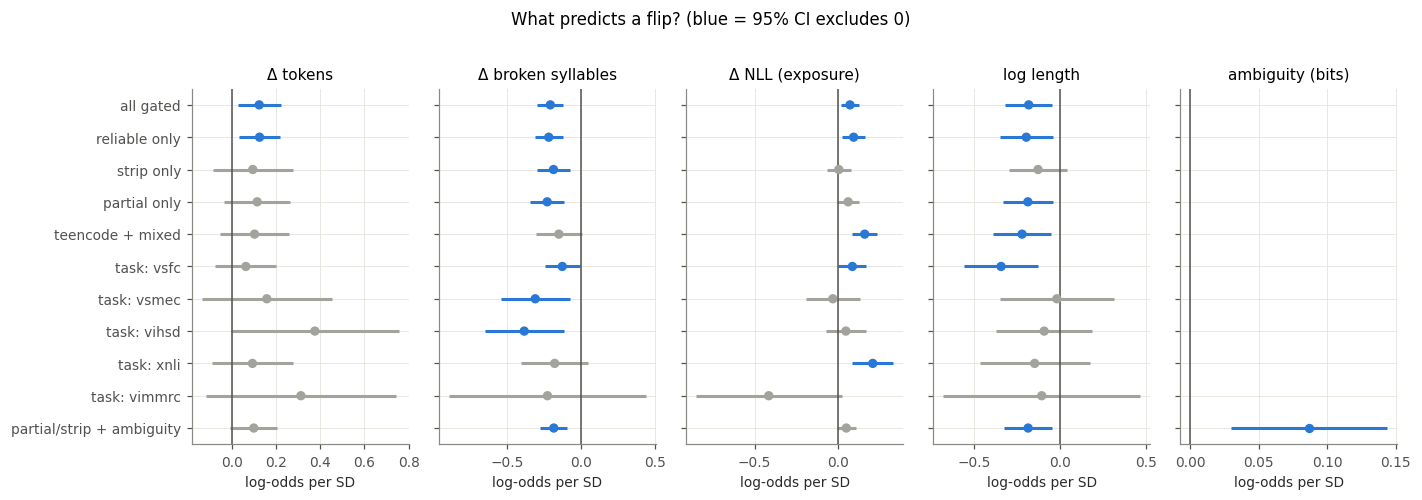

In [31]:
# Forest plot
show = ["all gated", "reliable only", "strip only", "partial only", "teencode + mixed"] + [f"task: {t}" for t in TASKS] + ["partial/strip + ambiguity"]
terms = ["z_d_tok", "z_d_broken", "z_d_nll", "z_log_len", "z_amb_bits"]
names = {"z_d_tok": "Δ tokens", "z_d_broken": "Δ broken syllables", "z_d_nll": "Δ NLL (exposure)", "z_log_len": "log length",
         "z_amb_bits": "ambiguity (bits)"}
fig, axes = plt.subplots(1, len(terms), figsize=(13, 4.4), sharey=True)
for ax, k in zip(axes, terms):
    d = ROB[ROB.term == k].set_index("spec").reindex(show)
    y = np.arange(len(show))
    ok = d.coef.notna().to_numpy()
    col = np.where((d.lo > 0) | (d.hi < 0), "#2a78d6", "#a3a29c")
    ax.hlines(y[ok], d.lo[ok], d.hi[ok], color=col[ok], lw=2)
    ax.scatter(d.coef[ok], y[ok], color=col[ok], s=26, zorder=3)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set(title=names[k], yticks=y, yticklabels=show, xlabel="log-odds per SD")
axes[0].invert_yaxis()
fig.suptitle("What predicts a flip? (blue = 95% CI excludes 0)", y=1.02)
plt.tight_layout()
save(fig, "fig09_item_level_forest")

### Same-tokenizer test

Within a group of models that tokenize every item identically (e.g. Qwen2.5 / Qwen3 / SeaLLMs-v3), `d_tok` and `d_broken` are the same for all of them on a given item. With **item × condition fixed effects** (and model fixed effects), the only thing left that differs is how surprising the noisy text is to each model (`d_nll`). If the model that finds the noisy item more surprising is the one that flips, exposure matters beyond tokenization.

Linear probability model, two-way fixed effects absorbed by alternating projections, SEs clustered by unit.

,sample,spec,term,coef_pp_per_sd,lo,hi,p,n
0,same tokenizer (item × cond × tokenizer FE),d_nll only,d_nll,2.423,1.145,3.702,0.000,45678
1,all models (item × cond FE),d_nll only,d_nll,2.235,1.240,3.229,0.000,60615
2,all models (item × cond FE),d_nll + tokenizer,d_nll,2.261,1.259,3.262,0.000,60615
3,all models (item × cond FE),d_nll + tokenizer,d_tok,-0.471,-1.979,1.038,0.541,60615
4,all models (item × cond FE),d_nll + tokenizer,d_broken,-0.788,-2.558,0.983,0.383,60615


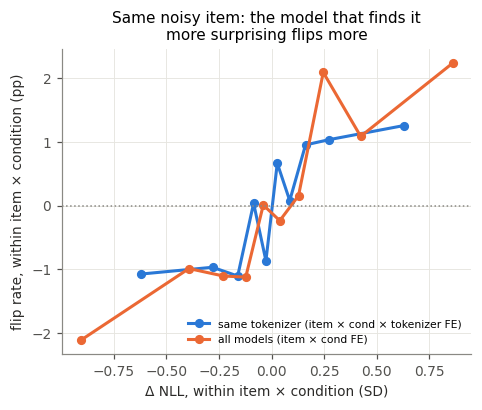

In [32]:
def demean(df, cols, groups, iters=100, tol=1e-10):
    out = df[cols].astype(float).copy()
    for _ in range(iters):
        delta = 0
        for g in groups:
            means = out.groupby(df[g]).transform("mean")
            out -= means
            delta = max(delta, float(np.abs(means.to_numpy()).max()))
        if delta < tol:
            break
    return out

X["tok_class"] = X.model.map(TOK_CLASS)
X["item_cond"] = X.task + "-" + X.item_id.astype(str) + "-" + X.cond
import statsmodels.api as sm
rows, binned = [], {}
SAMPLES = [("same tokenizer (item × cond × tokenizer FE)", X[X.tok_class.map(X.groupby("tok_class").model.nunique()) > 1], True),
           ("all models (item × cond FE)", X, False)]
for name, df, by_tok in SAMPLES:
    df = df.copy()
    df["grp"] = (df.tok_class + "|" + df.item_cond) if by_tok else df.item_cond
    df = df[df.grp.map(df.grp.value_counts()) > 1]
    cols = ["flip", "d_nll", "d_tok", "d_broken"]
    dm = demean(df, cols, ["grp", "model"])
    specs = [("d_nll only", ["d_nll"])] + ([] if by_tok else [("d_nll + tokenizer", ["d_nll", "d_tok", "d_broken"])])
    for spec, xs in specs:
        Z = dm[xs] / df[xs].std()
        r = sm.OLS(dm.flip, Z).fit(cov_type="cluster", cov_kwds={"groups": df.unit})
        for k in xs:
            rows.append({"sample": name, "spec": spec, "term": k, "coef_pp_per_sd": 100 * r.params[k],
                         "lo": 100 * r.conf_int().loc[k, 0], "hi": 100 * r.conf_int().loc[k, 1], "p": r.pvalues[k], "n": len(df)})
    binned[name] = (dm.d_nll / df.d_nll.std(), dm.flip)
ST = pd.DataFrame(rows)
save_table(ST.set_index(["sample", "spec", "term"]), "table_same_tokenizer", "Two-way FE linear probability model (percentage points per SD).")
display(ST.round(3))
KEY["same_tokenizer"] = ST.round(4).to_dict("records")

fig, ax = plt.subplots(figsize=(4.8, 3.6))
for (name, (xv, yv)), c in zip(binned.items(), ["#2a78d6", "#eb6834"]):
    q = pd.qcut(xv, 10, duplicates="drop")
    b = pd.DataFrame({"x": xv, "y": yv}).groupby(q, observed=True).mean()
    ax.plot(b.x, 100 * b.y, marker="o", color=c, label=name)
ax.axhline(0, color="#8a8984", lw=1, ls=":")
ax.set(xlabel="Δ NLL, within item × condition (SD)", ylabel="flip rate, within item × condition (pp)",
       title="Same noisy item: the model that finds it\nmore surprising flips more")
ax.legend(fontsize=7)
save(fig, "fig10_same_tokenizer")

## 5. Real noise in ViHSD, controlled for the label

Hate/offensive comments might be less accented *and* harder, which would fake a "real noise" effect. Here: accuracy on clean (as-collected) comments by original accent group, **within each label**, and a logistic model with label and model fixed effects.

items: accent group × label


label,bình thường,thù ghét,xúc phạm
group,,,
mostly unaccented,15,15,14
partly,39,16,23
fully accented,46,69,63


accuracy by group within label (gated models pooled):


label,bình thường,thù ghét,xúc phạm
group,,,
mostly unaccented,0.60,0.26,0.52
partly,0.76,0.38,0.53
fully accented,0.63,0.47,0.47


,models,spec,term,coef,lo,hi,p
0,gated,no label control,z_accent,0.039,-0.113,0.190,0.618
1,gated,label FE,z_accent,0.078,-0.071,0.227,0.303
2,gated,"label FE, groups",group[T.mostly unaccented],-0.299,-0.723,0.124,0.166
3,gated,"label FE, groups",group[T.partly],0.213,-0.150,0.576,0.250
4,reliable,no label control,z_accent,0.039,-0.114,0.192,0.619
5,reliable,label FE,z_accent,0.082,-0.070,0.235,0.291
6,reliable,"label FE, groups",group[T.mostly unaccented],-0.310,-0.747,0.127,0.164
7,reliable,"label FE, groups",group[T.partly],0.213,-0.154,0.580,0.256


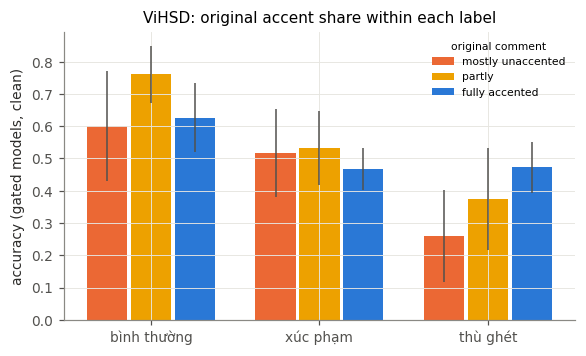

In [33]:
v = preds[(preds.task == "vihsd") & (preds.cond == "clean") & (preds.tier != "below gate")].merge(
    DATA["vihsd"][DATA["vihsd"].cond == "clean"][["item_id", "clean"]], on="item_id")
v["original_accent"] = v.clean.map(accent_share)
v["group"] = pd.cut(v.original_accent, [-0.01, 0.4, 0.7, 1.0], labels=["mostly unaccented", "partly", "fully accented"])
v["unit"] = v.item_id
items = v.drop_duplicates("item_id")
ct = pd.crosstab(items.group, items.label.map(dict(enumerate(TASK_SPECS["vihsd"]["labels"]))))
print("items: accent group × label"); display(ct)
by_label = v.pivot_table(index="group", columns=v.label.map(dict(enumerate(TASK_SPECS["vihsd"]["labels"]))), values="correct",
                         aggfunc="mean", observed=False)
print("accuracy by group within label (gated models pooled):"); display(by_label.round(2))
v["z_accent"] = (v.original_accent - v.original_accent.mean()) / v.original_accent.std()
rows = []
for name, df in [("gated", v), ("reliable", v[v.tier == "reliable"])]:
    for spec, f in [("no label control", "correct ~ z_accent + C(model)"),
                    ("label FE", "correct ~ z_accent + C(label) + C(model)"),
                    ("label FE, groups", "correct ~ C(group, Treatment('fully accented')) + C(label) + C(model)")]:
        r = smf.logit(f, data=df).fit(disp=0, cov_type="cluster", cov_kwds={"groups": df.unit})
        for k in [p for p in r.params.index if "accent" in p or "group" in p]:
            rows.append({"models": name, "spec": spec, "term": k.replace("C(group, Treatment('fully accented'))", "group"),
                         "coef": r.params[k], "lo": r.conf_int().loc[k, 0], "hi": r.conf_int().loc[k, 1], "p": r.pvalues[k]})
VH = pd.DataFrame(rows)
save_table(VH.set_index(["models", "spec", "term"]), "table_vihsd_natural_noise", "ViHSD: accuracy vs original accent share (logit).", "%.3f")
display(VH.round(3))
KEY["vihsd_natural"] = VH.round(4).to_dict("records")

fig, ax = plt.subplots(figsize=(6, 3.4))
labs = TASK_SPECS["vihsd"]["labels"]
groups = ["mostly unaccented", "partly", "fully accented"]
w = 0.26
for j, gname in enumerate(groups):
    vals, errs = [], []
    for k in range(3):
        s = v[(v.group == gname) & (v.label == k)].groupby("item_id").correct.mean()
        vals.append(s.mean() if len(s) else np.nan)
        errs.append(1.96 * s.std() / np.sqrt(len(s)) if len(s) > 1 else 0)
    ax.bar(np.arange(3) + (j - 1) * w, vals, w * 0.92, yerr=errs, color=["#eb6834", "#eda100", "#2a78d6"][j], label=gname,
           error_kw=dict(elinewidth=1, ecolor="#52514e"))
ax.set(xticks=range(3), xticklabels=labs, ylabel="accuracy (gated models, clean)", title="ViHSD: original accent share within each label")
ax.legend(fontsize=7, title="original comment", title_fontsize=7)
save(fig, "fig11_vihsd_natural_noise")

## 6. How predictions move under noise

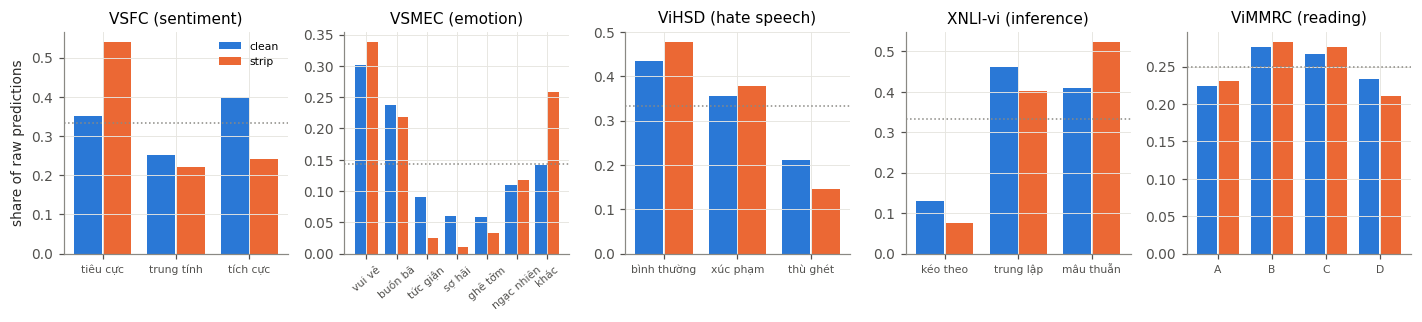

In [34]:
# Raw prediction shares, clean vs strip, reliable models pooled: does stripping push models toward one label?
fig, axes = plt.subplots(1, len(TASKS), figsize=(13, 3), sharey=False)
shift = {}
for ax, t in zip(axes, TASKS):
    g = preds[(preds.task == t) & (preds.tier == "reliable") & preds.cond.isin(["clean", "strip"])]
    if g.empty:
        ax.set_visible(False)
        continue
    sh = g.groupby("cond").pred_raw.value_counts(normalize=True).unstack().reindex(columns=range(K[t])).fillna(0)
    x = np.arange(K[t])
    ax.bar(x - 0.2, sh.loc["clean"], 0.38, color="#2a78d6", label="clean")
    ax.bar(x + 0.2, sh.loc["strip"], 0.38, color="#eb6834", label="strip")
    ax.axhline(1 / K[t], color="#8a8984", lw=1, ls=":")
    ax.set(xticks=x, xticklabels=TASK_SPECS[t]["labels"], title=TASK_NAME[t])
    ax.tick_params(axis="x", rotation=40 if K[t] > 4 else 0, labelsize=7)
    shift[t] = (sh.loc["strip"] - sh.loc["clean"]).round(3).tolist()
axes[0].set_ylabel("share of raw predictions")
axes[0].legend(fontsize=7)
plt.tight_layout()
save(fig, "fig12_prediction_shift")
KEY["raw_prediction_shift_strip_minus_clean"] = shift

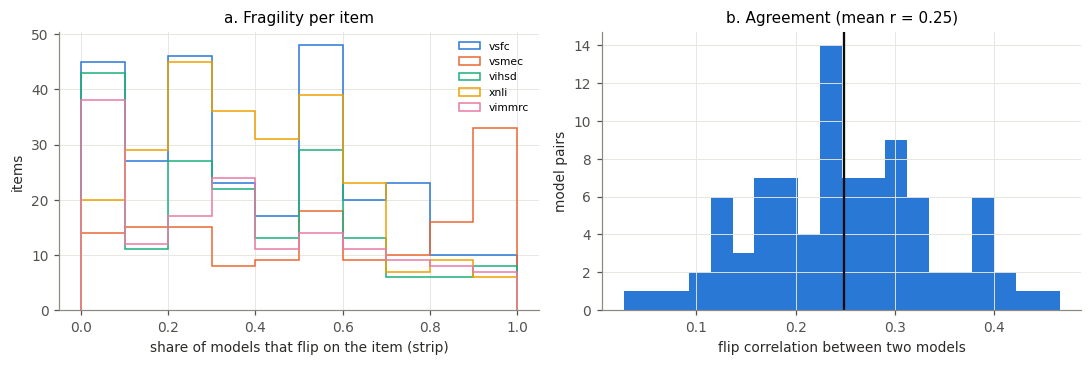

,task,item_id,mean,size,clean_text,strip_text
0,vsfc,194,1.0,3,không điểm danh .,khong diem danh .
1,xnli,231,1.0,4,"Tổ chức tên (nếu có) Địa chỉ Thành phố, mã bưu chính của Tiểu bang\nHãy tạo ra một cái...","To chuc ten (neu co) Dia chi Thanh pho, ma buu chinh cua Tieu bang\nHay tao ra mot cai..."
2,vsfc,207,1.0,8,cô max có tâm .,co max co tam .
3,vimmrc,140,1.0,5,"1. Xưa có chàng trai thấy một bọn trẻ định giết con rắn nước liền bỏ tiền ra mua, rồi ...","1. Xua co chang trai thay mot bon tre dinh giet con ran nuoc lien bo tien ra mua, roi ..."
4,vsfc,239,1.0,10,"thầy chịu khó , dạy kỹ nếu sinh viên chưa hiểu .","thay chiu kho , day ky neu sinh vien chua hieu ."
5,vimmrc,158,1.0,3,"1. Trung đoàn trưởng bước vào lán, nhìn cả đội một lượt. Cặp mắt ông ánh lên vẻ trìu m...","1. Trung doan truong buoc vao lan, nhin ca doi mot luot. Cap mat ong anh len ve triu m..."
6,vsmec,7,1.0,8,mấy đứa thấy mình hiền nó làm tới hà .. quá đáng lắm luôn á !,may dua thay minh hien no lam toi ha .. qua dang lam luon a !
7,vsmec,10,1.0,7,mày bị ngu hả đĩ chó :) hết chỗ viết à :) thích viết thì tìm chỗ nào đéo trôi á :) hoặ...,may bi ngu ha di cho :) het cho viet a :) thich viet thi tim cho nao deo troi a :) hoa...
8,vsmec,15,1.0,6,đã bị đuổi 1 lần . đéo lgi cũng bị dí,da bi duoi 1 lan . deo lgi cung bi di
9,vimmrc,52,1.0,10,"Ngay giữa sân trường, sừng sững một cây bàng. Mùa đông, cây vươn dài những cành khẳng ...","Ngay giua san truong, sung sung mot cay bang. Mua dong, cay vuon dai nhung canh khang ..."


In [35]:
# Do models agree on WHICH items are fragile? Per item flip rate under strip, and pairwise flip correlation
fl = X[(X.cond == "strip") & (X.tier == "reliable")]
item_rate = fl.groupby(["task", "item_id"]).flip.agg(["mean", "size"])
item_rate = item_rate[item_rate["size"] >= 3]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for i, t in enumerate(TASKS):
    s = item_rate.loc[t]["mean"] if t in item_rate.index.get_level_values(0) else pd.Series(dtype=float)
    axes[0].hist(s, bins=np.linspace(0, 1, 11), histtype="step", lw=2, color=PALETTE[i], label=t)
axes[0].set(xlabel="share of models that flip on the item (strip)", ylabel="items", title="a. Fragility per item")
axes[0].legend(fontsize=7)
# pairwise phi between models on items both got right when clean
W = fl.pivot_table(index=["task", "item_id"], columns="model", values="flip")
cors = W.corr(min_periods=50)
vals = cors.where(np.triu(np.ones(cors.shape, bool), 1)).stack()
axes[1].hist(vals, bins=20, color="#2a78d6")
axes[1].axvline(vals.mean(), color="#0b0b0b", lw=1.5)
axes[1].set(xlabel="flip correlation between two models", ylabel="model pairs", title=f"b. Agreement (mean r = {vals.mean():.2f})")
plt.tight_layout()
save(fig, "fig13_flip_agreement")
KEY["flip_agreement_mean_r"] = round(float(vals.mean()), 3)
# the most fragile items, for the qualitative section of the paper
frag = item_rate.sort_values("mean", ascending=False).groupby(level=0).head(3).reset_index()
frag["clean_text"] = [DATA[t][(DATA[t].item_id == i) & (DATA[t].cond == "clean")].clean.iloc[0][:140] for t, i in zip(frag.task, frag.item_id)]
frag["strip_text"] = [DATA[t][(DATA[t].item_id == i) & (DATA[t].cond == "strip")].text.iloc[0][:140] for t, i in zip(frag.task, frag.item_id)]
frag.to_csv(f"{OUT_DIR}/tables/most_fragile_items.csv", index=False)
display(frag)

## 7. Headline numbers

In [36]:
def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o
json.dump(jsonable(KEY), open(f"{OUT_DIR}/key_numbers.json", "w"), ensure_ascii=False, indent=1)
print(json.dumps(jsonable(KEY), ensure_ascii=False)[:20000])
print("\nfigures:", sorted(os.listdir(f"{OUT_DIR}/figures")))

{"items_identical_to_run": "9135/9135", "integrity_failures": 0, "model_task_files": 80, "tiers": {"reliable": 52, "gated": 19, "below gate": 9}, "free_vs_scored_agreement": 0.72, "dose_response_kept_mean": {"vsfc": {"0": 1.0, "25": 0.809, "50": 0.683, "75": 0.561, "100": 0.432}, "vsmec": {"0": 1.0, "25": 0.805, "50": 0.644, "75": 0.548, "100": 0.444}, "vihsd": {"0": 1.0, "25": 0.987, "50": 0.785, "75": 0.681, "100": 0.586}, "xnli": {"0": 1.0, "25": 0.705, "50": 0.571, "75": 0.461, "100": 0.478}, "vimmrc": {"0": 1.0, "25": 0.822, "50": 0.699, "75": 0.648, "100": 0.639}}, "dose_monotone_share": 0.635, "mean_normdrop_strip_reliable": {"vihsd": 0.414, "vimmrc": 0.361, "vsfc": 0.568, "vsmec": 0.556, "xnli": 0.522}, "mean_normdrop_teencode_reliable": {"vihsd": 0.034, "vimmrc": 0.026, "vsfc": 0.066, "vsmec": 0.021, "xnli": 0.102}, "scale_diffs": [{"task": "vsfc", "family": "Qwen2.5", "small": "Qwen2.5-1.5B", "large": "Qwen2.5-7B", "nd_small": 0.729, "nd_large": 0.208, "diff": 0.521, "lo": 0.

When done: `Runtime → Disconnect and delete runtime`.